# AR tuning experiments — repeated paths and Jones-sampled models

This notebook implements **experiments 2 and 3** under **Tuning experiments** in the [AR thesis chapter](../../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex): experiment 2 uses a configurable number of independent AR(3) realizations with fixed coefficients. Experiment 3 draws fresh coefficient vectors using Jones’s method and simulates one path for each vector. Both experiments use one common fixed starting direction and tune absolute geometric steps.

For experiment 2, the fixed model is $X_t=0.6X_{t-1}-0.3X_{t-2}+0.2X_{t-3}+\varepsilon_t$, with $T=500$ and independent $\varepsilon_t\sim U(-1,1)$. The same coefficient vector appears in [Arbúes et al. (2013), §5.3, p. 13, with $b=0$](https://www.ucm.es/data/cont/docs/518-2013-11-05-Arbues_Feb19.pdf#page=13). It is a simulation precedent for the coefficients; the innovation choice here follows the thesis.

**Dimension convention:** newest-first windows have $k=p+1=4$ coordinates, so the starting direction is on $S^3$. The thesis currently writes $S^2$ in this paragraph; this notebook uses the four-dimensional embedding and does not edit the thesis.

The optimizer and grid search live in shared modules: [descent.py](../ar_tools/descent.py) and [tuning.py](../ar_tools/tuning.py). Each displayed figure is also exported as PDF and PNG. Experiments 2 and 3 select all configurations with the highest absolute-gap co-winner count. Experiment 2 additionally reports a separate coefficient-error co-winner count using the known simulation coefficients; the width counter is unchanged.

A final win-frequency comparison awards +1 to every configuration whose achieved minimum empirical width is within an absolute tolerance $\varepsilon=10^{-8}$ of the best achieved value on each realization. Win-count rankings and matrices are shown for the repeated-path experiments. Experiment 2 adds coefficient MAE counts with their own tolerance $\varepsilon_{\mathrm{MAE}}=10^{-2}$.
Both experiments use a **2,000-iteration cap and patience 200**.


In [45]:
import hashlib
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display

AR_CODE_DIR = next(
    candidate.resolve()
    for root in (Path.cwd(), *Path.cwd().parents)
    for candidate in (root / "Code" / "Code_AR_processes", root)
    if (candidate / "ar_tools/functions.py").is_file()
)
PROJECT_ROOT = AR_CODE_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Refresh the optimizer as well as the tuner in an existing notebook kernel.
from Code.Code_AR_processes.ar_tools import descent as descent_tools
descent_tools = importlib.reload(descent_tools)
from Code.Code_AR_processes.ar_tools.functions import is_stationary
# Refresh the local tuning helpers when setup is rerun in an existing kernel.
from Code.Code_AR_processes.ar_tools import tuning as tuning_tools
tuning_tools = importlib.reload(tuning_tools)
from Code.Code_AR_processes.ar_tools.tuning import (
    tune_fixed_ar_realizations, tune_jones_ar_realizations,
    summarize_configuration_wins,
)
with plt.rc_context():
    from Code.Code_AR_processes.ar_tools import tuning_plots as tuning_plot_tools
    tuning_plot_tools = importlib.reload(tuning_plot_tools)
    from Code.Code_AR_processes.ar_tools.tuning_plots import plot_tuning_matrices

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"font.size": 10, "pdf.fonttype": 42})
np.set_printoptions(precision=8, suppress=True)
EXPERIMENT_NAME = "ar_tuning_experiments"
OUTPUT_ROOT = AR_CODE_DIR / "outputs"

from Code.Code_AR_processes.ar_tools.coefficient_errors import coefficient_mae


## Fixed settings and tuning grids

The grid is exactly $H\in\{2,5,10,20,50,100,200,1000\}$ and $s\in\{0.1,0.2,\ldots,0.9\}$, with $\beta=2^{-1/H}$. Each grid value $s$ is used directly as the initial step $\gamma_0$.

Both experiments use a **2,000-iteration cap and patience 200**. `improvement_tolerance=0` records every strictly smaller width and resets the patience counter. The win-frequency comparison awards +1 to every configuration whose achieved width is at most the best achieved width plus `epsilon_win_tolerance` (default $10^{-8}$). The simulator discards 2,000 burn-in observations, a retained convention from the previous tuning notebook. Seeds and burn-in are explicit experimental settings, not fitted parameters. [Thesis: termination and tuning paragraphs](../../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex), [simulation](../ar_tools/functions.py), [stopping rule](../ar_tools/descent.py).

Set **`number_of_realizations`** in the next cell to choose the number of independent paths in experiment 2 (default: **100**). The simulation, win-count summaries and matrices all use this setting.
Experiment 2 also awards a separate +1 for coefficient MAE within `coefficient_epsilon_win_tolerance` (default $10^{-2}$) of that path's smallest coefficient error. These two tolerances are independently adjustable. [Counting implementation](../ar_tools/tuning.py), `summarize_configuration_wins`.


In [46]:
T = 500
p = 3
phi = np.array([0.6, -0.3, 0.2], dtype=float)
burnin = 2_000
optimizer_seed = 20261019
embedding_dimension = p + 1

max_iterations = 2_000
patience = 200
improvement_tolerance = 0.0
scale_grid = np.arange(1, 10) / 10.0  # 0.1, 0.2, ..., 0.9
half_life_grid = np.array([2, 5, 10, 20, 50, 100, 200, 1000])

number_of_realizations = 100  # CHANGE THIS: number of independent paths in experiment 2.
realization_process_seed = 20261020

epsilon_win_tolerance = 1e-8  # CHANGE THIS: absolute distance from each path's best achieved width.
coefficient_epsilon_win_tolerance = 1e-2  # CHANGE THIS: distance from each path's smallest coefficient MAE.

if p != 3 or phi.shape != (p,) or embedding_dimension != 4:
    raise ValueError("This experiment requires an AR(3) model and four-coordinate windows.")
stationary, companion_eigenvalues = is_stationary(phi)
if not stationary or phi[-1] == 0:
    raise ValueError("Choose a causal AR(3) coefficient vector with nonzero phi_3.")
if T < embedding_dimension + 1 or burnin < 0:
    raise ValueError("Use enough observations to form at least two windows and nonnegative burn-in.")

if (isinstance(number_of_realizations, (bool, np.bool_))
        or not isinstance(number_of_realizations, (int, np.integer))
        or number_of_realizations < 1):
    raise ValueError("number_of_realizations must be a positive integer.")
for tolerance in (epsilon_win_tolerance, coefficient_epsilon_win_tolerance):
    if (isinstance(tolerance, (bool, np.bool_))
            or not isinstance(tolerance, (int, float, np.integer, np.floating))
            or not np.isfinite(tolerance) or tolerance < 0):
        raise ValueError("Both win tolerances must be finite nonnegative numbers.")


## Fix the common starting direction and export settings

Generate one standard Gaussian four-vector using `optimizer_seed` and normalize it to obtain `initial_direction`. Experiments 2 and 3 reuse this exact direction for every configuration and realization. This is the initialization construction used by the [shared descent implementation](../ar_tools/descent.py).

Each experiment simulates its own paths through the [shared runners](../ar_tools/tuning.py), `tune_fixed_ar_realizations` and `tune_jones_ar_realizations`. The setup below prepares the fixed-coefficient experiment's reproducible settings and PDF/PNG output directories.


In [47]:
initial_direction = np.random.default_rng(optimizer_seed).normal(size=embedding_dimension)
initial_direction /= np.linalg.norm(initial_direction)

configuration = {
    "experiment": "fixed_phi_realizations", "coefficient_error_metric": "mae_per_coefficient_v1", "T": int(T), "p": int(p), "phi": phi.tolist(),
    "burnin": int(burnin), "innovation_distribution": "Uniform(-1,1)",
    "process_seed": int(realization_process_seed), "optimizer_seed": int(optimizer_seed),
    "initial_direction": initial_direction.tolist(), "starts": 1,
    "max_iterations": int(max_iterations), "stopping": "iteration_limit_or_patience", "patience": int(patience),
    "improvement_tolerance": float(improvement_tolerance),
    "scale_grid": scale_grid.tolist(), "half_life_grid": half_life_grid.tolist(),
    "step_rules": ["absolute"],
    "selection": "all highest absolute-gap co-winner counts; parameter labels order ties for display",
    "replications": int(number_of_realizations),
    "win_frequency": {"score": "minimum_width", "credit": "one_per_absolute_gap_qualifier",
                      "epsilon": float(epsilon_win_tolerance)},
    "coefficient_win_frequency": {"score": "coefficient_mae",
                                  "credit": "one_per_absolute_gap_qualifier",
                                  "epsilon": float(coefficient_epsilon_win_tolerance)},
    "source_sha256": hashlib.sha256(b"".join(
        (AR_CODE_DIR / "ar_tools" / name).read_bytes()
        for name in ["functions.py", "innovations.py", "descent.py", "tuning.py", "tuning_plots.py", "coefficient_errors.py"]
    )).hexdigest(),
}
run_id = hashlib.sha256(repr(sorted(configuration.items())).encode()).hexdigest()[:16]
PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / run_id
IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / run_id
for directory in (PDF_DIR, IMAGE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print(f"Experiment 2 run {run_id}: {number_of_realizations} paths, T={T}, one fixed starting direction")
print(f"True coefficients: {phi}; companion spectral radius: {np.max(np.abs(companion_eigenvalues)):.8f}")
print(f"Fixed starting direction: {initial_direction}")

Experiment 2 run 5cb3193fa62e367c: 100 paths, T=500, one fixed starting direction
True coefficients: [ 0.6 -0.3  0.2]; companion spectral radius: 0.62876280
Fixed starting direction: [ 0.0469043  -0.81156153  0.31282302  0.49123275]


## Experiment 2: fresh realizations, fixed coefficients and start

Keep $T=500$, $\phi=(0.6,-0.3,0.2)$, the innovation law, grids, budgets and **the fixed starting direction** from the shared setup. Only the innovation path changes. `number_of_realizations` controls the number of paths from a separate seed stream. Every configuration uses the same cloud within each replication. Each configuration uses the same initial step $\gamma_0$ on every path.

Record every configuration's smallest achieved empirical width on every path, then select **all configurations with the highest absolute-gap co-winner count** in the section below. The paired runs and per-path grid winners remain in `realization_results` and `realization_cases`. A separate coefficient-error counter compares the recovered coefficients with the known simulation coefficients, using its own tolerance. The two counters are reported separately. [Shared runner and counting rule](../ar_tools/tuning.py), `tune_fixed_ar_realizations(..., summarize=False)` and `summarize_configuration_wins`.

All runs use a **2,000-iteration cap and patience 200**. Selection uses no external optimum calculation or relative-gap target. Results stay in the notebook and memory; only PDF/PNG figures are exported. This experiment varies innovations conditional on one model and starting direction. Experiment 3 varies the coefficients; random-start sensitivity remains future work.

Each progress line reports the coefficient estimates and their MAE for that path's lowest-width grid result. The table below the run shows the same diagnostics; the shared [runner](../ar_tools/tuning.py) computes them from the selected direction.


In [48]:
realization_experiment = tune_fixed_ar_realizations(
    phi, T, initial_direction, scale_grid, half_life_grid,
    replications=number_of_realizations, process_seed=realization_process_seed,
    burnin=burnin, iterations=max_iterations, patience=patience,
    improvement_tolerance=improvement_tolerance, optimizer_seed=optimizer_seed,
    progress=True, summarize=False,
)
realization_results = pd.DataFrame(realization_experiment["results"])
realization_cases = pd.DataFrame(realization_experiment["cases"])
np.testing.assert_allclose(realization_experiment["initial_direction"], initial_direction, atol=1e-15, rtol=0)
assert len(realization_results) == number_of_realizations * len(scale_grid) * len(half_life_grid)
assert realization_results["total_evaluations"].between(1, max_iterations).all()
assert realization_cases["process_seed"].is_unique
print(f"Completed {len(realization_cases)} fresh paths and {len(realization_results)} labeled runs.")
print(f"Original stopping rule: at most {max_iterations} evaluated iterations, patience={patience}.")
print(f"Fixed starting direction: {initial_direction}")
print("Per-path attained-width grid winners (diagnostics):")
realization_case_columns = [
    "replication", "T", "process_seed", "grid_best_width",
    "estimated_phi_1", "estimated_phi_2", "estimated_phi_3", "coefficient_mae",
    "grid_winner_step_value", "grid_winner_half_life", "runtime_seconds",
]
with pd.option_context("display.max_columns", None, "display.precision", 8):
    display(realization_cases[realization_case_columns])


Path 1/100, T=500: best achieved width=1.6259109893, estimated phi=[ 0.598155, -0.290496,  0.193742], coefficient MAE=0.0058687489, 72 absolute schedules; 1.1s
Path 2/100, T=500: best achieved width=1.6107654881, estimated phi=[ 0.628149, -0.31332 ,  0.204348], coefficient MAE=0.015272389, 72 absolute schedules; 0.9s
Path 3/100, T=500: best achieved width=1.6136578771, estimated phi=[ 0.786643, -0.413632,  0.270238], coefficient MAE=0.12350415, 72 absolute schedules; 0.9s
Path 4/100, T=500: best achieved width=1.6177427651, estimated phi=[ 0.601161, -0.300805,  0.18938 ], coefficient MAE=0.0041954213, 72 absolute schedules; 1.0s
Path 5/100, T=500: best achieved width=1.6049133702, estimated phi=[ 0.708119, -0.418089,  0.270003], coefficient MAE=0.098737038, 72 absolute schedules; 0.9s
Path 6/100, T=500: best achieved width=1.6065023152, estimated phi=[ 1.322079, -0.983561,  0.566309], coefficient MAE=0.59064946, 72 absolute schedules; 1.3s
Path 7/100, T=500: best achieved width=1.60982

,replication,T,process_seed,grid_best_width,estimated_phi_1,estimated_phi_2,estimated_phi_3,coefficient_mae,grid_winner_step_value,grid_winner_half_life,runtime_seconds
0,1,500,15285170486174312110,1.62591099,0.59815513,-0.29049636,0.19374226,0.00586875,0.4,20.0,1.08927621
1,2,500,2977048524731513747,1.61076549,0.62814864,-0.31332031,0.20434822,0.01527239,0.3,10.0,0.90868529
2,3,500,9700859109571484927,1.61365788,0.78664263,-0.41363187,0.27023795,0.12350415,0.4,10.0,0.90869075
3,4,500,10916039272464303899,1.61774277,0.60116142,-0.30080531,0.18938047,0.00419542,0.7,10.0,0.98911913
4,5,500,1062370734165657769,1.60491337,0.70811905,-0.41808936,0.27000270,0.09873704,0.1,100.0,0.93402113
...,...,...,...,...,...,...,...,...,...,...,...
95,96,500,5600466015318381656,1.62510305,0.60911725,-0.29556493,0.21043290,0.00799507,0.3,10.0,0.86419838
96,97,500,13729803690704503133,1.60435344,0.68199125,-0.38029145,0.26150139,0.07459470,0.6,10.0,0.94346962
97,98,500,9790441807068529897,1.60935127,0.63816212,-0.30466578,0.23582884,0.02621891,0.6,50.0,0.89365829
98,99,500,15627298590695882592,1.60930654,0.66126904,-0.34167110,0.21333042,0.03875685,0.1,50.0,1.03420358


## Win frequency: absolute-gap co-winners

On each of the **same configured realizations** from experiment 2, record each configuration's smallest achieved empirical width:
$$f_r(\theta)=\min_{t\,\mathrm{evaluated}}\hat w_{r,T}(u_{r,t}(\theta)).$$
Award a full **+1 to every configuration** satisfying
$$f_r(\theta)\le\min_{\eta\in\Theta}f_r(\eta)+\varepsilon,\qquad \varepsilon=10^{-8},$$
and count these credits over the configured paths:
$$N_\varepsilon(\theta)=\sum_{r=1}^R\mathbf{1}\!\left\{f_r(\theta)\le\min_{\eta\in\Theta}f_r(\eta)+\varepsilon\right\}.$$
The reference is the best achieved value among the tested configurations on the same path. Scores are compared at full precision against this absolute threshold. This is the defined counting rule for this experiment. [Counting implementation](../ar_tools/tuning.py), `summarize_configuration_wins(..., epsilon=...)`.

Change **`epsilon_win_tolerance`** in the settings cell to choose the absolute tolerance. Reuse `realization_results` from the **2,000-iteration cap / patience 200** descents above, with the same grid, starting direction and process seeds. The optimizer retains its existing settings. All qualifying configurations receive a full point regardless of speed; zero-win configurations remain in the ranking. Each configuration can receive at most $R$ points, while the total across configurations can exceed $R$. All configurations with the highest final count are displayed and highlighted. Equal counts are ordered by parameter labels for display only; every tied leader is retained.

Tolerance-based comparison with a best achieved objective has precedent in [Moré and Wild, §2.1, equation (2.2)](https://optimization-online.org/wp-content/uploads/2008/01/1883.pdf#page=7); their tolerance is scaled by the objective reduction. The fixed absolute tolerance and full +1 credit used here are experimental choices. Tables stay in the notebook; only PDF/PNG figures are exported.

In [49]:
epsilon_win_experiment = summarize_configuration_wins(
    realization_results.to_dict("records"),
    score_key="minimum_width", epsilon=epsilon_win_tolerance,
)
epsilon_win_step_ranges = realization_results.groupby("candidate_id", as_index=False).agg(
    gamma0_min=("gamma0", "min"), gamma0_max=("gamma0", "max"),
)
epsilon_win_ranking = pd.DataFrame(epsilon_win_experiment["ranking"]).rename(
    columns={"rank": "win_rank"},
).merge(epsilon_win_step_ranges, on="candidate_id", validate="one_to_one").sort_values("win_rank")
epsilon_win_leaders = epsilon_win_ranking.loc[
    epsilon_win_ranking["wins"] == epsilon_win_ranking["wins"].max()
].copy()
epsilon_win_winners = pd.DataFrame(epsilon_win_experiment["winners"])
epsilon_win_cases = pd.DataFrame(epsilon_win_experiment["case_summaries"])
assert epsilon_win_experiment["epsilon"] == epsilon_win_tolerance
assert epsilon_win_experiment["cases"] == number_of_realizations
assert epsilon_win_ranking["wins"].between(0, number_of_realizations).all()
assert epsilon_win_ranking["wins"].sum() == len(epsilon_win_winners) == epsilon_win_experiment["total_points"]
assert epsilon_win_cases["co_winners"].sum() == len(epsilon_win_winners)
assert not epsilon_win_winners.duplicated(["replication", "T", "candidate_id"]).any()
assert (epsilon_win_winners["winning_score"] <= epsilon_win_winners["winning_threshold"]).all()

epsilon_win_columns = [
    "win_rank", "step_rule", "step_value", "half_life", "beta",
    "wins", "win_rate", "mean_evaluations",
]

print(f"Tuning {number_of_realizations} paths: cap {max_iterations}, patience {patience}.")
print(f"+1 to EVERY configuration with achieved width <= path minimum + {epsilon_win_tolerance:g}.")
with pd.option_context("display.max_columns", None, "display.precision", 10):
    display(epsilon_win_ranking[epsilon_win_columns].head(15))
    print("All configurations with the highest absolute-gap win count:")
    display(epsilon_win_leaders[epsilon_win_columns])
print(f"{epsilon_win_experiment['cases']} realizations; {epsilon_win_experiment['total_points']} full +1 credits; "
      f"{epsilon_win_experiment['tied_cases']} paths with multiple co-winners; "
      f"maximum {epsilon_win_experiment['maximum_co_winners']} co-winners on one path.")
for choice in epsilon_win_leaders.to_dict("records"):
    print(f"Absolute-gap win-count leader: {choice['step_rule']}, scale={choice['step_value']:g}, "
          f"H={choice['half_life']:g}, beta={choice['beta']:.12g}; "
          f"wins={int(choice['wins'])}/{number_of_realizations}.")

Tuning 100 paths: cap 2000, patience 200.
+1 to EVERY configuration with achieved width <= path minimum + 1e-08.


,win_rank,step_rule,step_value,half_life,beta,wins,win_rate,mean_evaluations
0,1,absolute,0.7,50.0,0.9862327045,71,0.71,1954.27
1,2,absolute,0.8,50.0,0.9862327045,68,0.68,2000.00
2,3,absolute,0.2,50.0,0.9862327045,67,0.67,1979.94
3,4,absolute,0.6,50.0,0.9862327045,67,0.67,1927.54
4,5,absolute,0.3,50.0,0.9862327045,66,0.66,1995.69
5,6,absolute,0.5,50.0,0.9862327045,65,0.65,1900.09
6,7,absolute,0.4,50.0,0.9862327045,64,0.64,1926.74
7,8,absolute,0.9,50.0,0.9862327045,63,0.63,1941.57
8,9,absolute,0.3,20.0,0.9659363289,45,0.45,1183.64
9,10,absolute,0.1,50.0,0.9862327045,43,0.43,1983.27


All configurations with the highest absolute-gap win count:


,win_rank,step_rule,step_value,half_life,beta,wins,win_rate,mean_evaluations
0,1,absolute,0.7,50.0,0.9862327045,71,0.71,1954.27


100 realizations; 1054 full +1 credits; 82 paths with multiple co-winners; maximum 28 co-winners on one path.
Absolute-gap win-count leader: absolute, scale=0.7, H=50, beta=0.986232704493; wins=71/100.


### Coefficient MAE co-winners on the same paths

For this simulated experiment, define the coefficient error of each configuration's recorded minimum-width direction by
$$e_r(\theta)=\frac1p\|\hat\phi_r(\theta)-\phi\|_1
=\frac1p\sum_{j=1}^{p}|\hat\phi_{r,j}(\theta)-\phi_j|,\qquad
\hat\phi_{r,j}(\theta)=-\frac{u_{r,j}(\theta)}{u_{r,0}(\theta)}.$$
This is the experiment's error diagnostic, computed from the returned directions in [the shared grid implementation](../ar_tools/tuning.py), `tune_geometric_half_life_schedules`.

Independently of the width counter, award **+1 to every configuration** satisfying
$$e_r(\theta)\le\min_{\eta\in\Theta:\ e_r(\eta)\ \mathrm{finite}}e_r(\eta)
+\varepsilon_{\mathrm{MAE}},\qquad\varepsilon_{\mathrm{MAE}}=10^{-2},$$
then add the credits across all configured paths. Change **`coefficient_epsilon_win_tolerance`** in the settings cell to adjust this tolerance separately from `epsilon_win_tolerance` ($10^{-8}$ for widths). The minimum is taken across the absolute-step grid on each path, and every qualifying configuration gets a full point, including ties. All comparisons use full precision. This counting rule is an experimental choice; [implementation](../ar_tools/tuning.py), `summarize_configuration_wins(..., score_key="coefficient_mae", allow_nonfinite=True)`.

Reuse the same recorded minimum-width directions: no new simulations or descents are needed. If $|u_{r,0}|\le10^{-10}$ or coefficients are nonfinite, report the coefficient error as undefined and award no coefficient point; an entirely undefined path awards no coefficient points. Undefined counts remain visible. The underlying width results remain available. Coefficient-error selection uses the known simulation truth.

The matrix below displays **width-win counts (W)** above **coefficient-error win counts (MAE)** in each cell. Red boxes mark all highest width counts; green boxes mark all highest coefficient-error counts. Nested boxes show a shared leader. Cell colors encode width counts. [Matrix plotting implementation](../ar_tools/tuning_plots.py), `plot_tuning_matrices`.


In [50]:
# Recover coefficients from each configuration's recorded minimum-width direction.
realization_coefficient_diagnostics = realization_results.copy()
realization_directions = realization_results[[f"u_{j}" for j in range(p + 1)]].to_numpy(dtype=float)
realization_coefficients = np.full((len(realization_results), p), np.nan)
realization_coefficient_valid = (
    np.isfinite(realization_directions).all(axis=1) & (np.abs(realization_directions[:, 0]) > 1e-10)
)
with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
    np.divide(-realization_directions[:, 1:], realization_directions[:, :1],
              out=realization_coefficients, where=realization_coefficient_valid[:, None])
    realization_coefficient_errors = coefficient_mae(realization_coefficients, phi)
realization_coefficient_valid &= (
    np.isfinite(realization_coefficients).all(axis=1) & np.isfinite(realization_coefficient_errors)
)
realization_coefficient_errors[~realization_coefficient_valid] = np.nan
for j in range(p):
    realization_coefficient_diagnostics[f"estimated_phi_{j+1}"] = realization_coefficients[:, j]
realization_coefficient_diagnostics["coefficient_valid"] = realization_coefficient_valid
realization_coefficient_diagnostics["coefficient_mae"] = realization_coefficient_errors

coefficient_win_experiment = summarize_configuration_wins(
    realization_coefficient_diagnostics.to_dict("records"), score_key="coefficient_mae",
    epsilon=coefficient_epsilon_win_tolerance, allow_nonfinite=True,
)
coefficient_win_ranking = pd.DataFrame(coefficient_win_experiment["ranking"]).rename(
    columns={"rank": "coefficient_win_rank", "wins": "coefficient_wins",
             "win_rate": "coefficient_win_rate", "undefined_scores": "undefined_coefficients"},
)
coefficient_win_leaders = coefficient_win_ranking.loc[
    coefficient_win_ranking["coefficient_wins"] == coefficient_win_ranking["coefficient_wins"].max()
].copy()
coefficient_win_winners = pd.DataFrame(coefficient_win_experiment["winners"])
coefficient_win_cases = pd.DataFrame(coefficient_win_experiment["case_summaries"])
combined_win_ranking = epsilon_win_ranking.merge(
    coefficient_win_ranking[["candidate_id", "coefficient_win_rank", "coefficient_wins",
                             "coefficient_win_rate", "undefined_coefficients"]],
    on="candidate_id", validate="one_to_one",
)
assert coefficient_win_experiment["epsilon"] == coefficient_epsilon_win_tolerance
assert coefficient_win_experiment["cases"] == number_of_realizations
assert coefficient_win_ranking["coefficient_wins"].between(0, number_of_realizations).all()
assert coefficient_win_ranking["coefficient_wins"].sum() == len(coefficient_win_winners)
assert coefficient_win_cases["co_winners"].sum() == coefficient_win_experiment["total_points"]
if not coefficient_win_winners.empty:
    assert not coefficient_win_winners.duplicated(["replication", "T", "candidate_id"]).any()
    assert (coefficient_win_winners["winning_score"] <= coefficient_win_winners["winning_threshold"]).all()

coefficient_win_columns = [
    "coefficient_win_rank", "step_rule", "step_value", "half_life", "beta",
    "coefficient_wins", "coefficient_win_rate", "undefined_coefficients",
]
print(f"+1 to EVERY configuration with coefficient MAE <= path minimum + {coefficient_epsilon_win_tolerance:g}.")
with pd.option_context("display.max_columns", None, "display.precision", 10):
    display(coefficient_win_ranking[coefficient_win_columns].head(15))
    print("All configurations with the highest coefficient-error win count:")
    display(coefficient_win_leaders[coefficient_win_columns])
print(f"{coefficient_win_experiment['cases']} realizations; {coefficient_win_experiment['total_points']} full +1 coefficient credits; "
      f"{coefficient_win_experiment['tied_cases']} paths with multiple coefficient co-winners.")
print(f"Undefined coefficient estimates: {(~realization_coefficient_valid).sum()}; "
      f"paths with no finite coefficient estimate: {coefficient_win_experiment['undefined_cases']}.")


+1 to EVERY configuration with coefficient MAE <= path minimum + 0.01.


,coefficient_win_rank,step_rule,step_value,half_life,beta,coefficient_wins,coefficient_win_rate,undefined_coefficients
0,1,absolute,0.2,50.0,0.9862327045,68,0.68,0
1,2,absolute,0.3,100.0,0.9930924954,67,0.67,0
2,3,absolute,0.7,50.0,0.9862327045,67,0.67,0
3,4,absolute,0.8,50.0,0.9862327045,66,0.66,0
4,5,absolute,0.2,100.0,0.9930924954,65,0.65,0
5,6,absolute,0.3,50.0,0.9862327045,65,0.65,0
6,7,absolute,0.5,100.0,0.9930924954,65,0.65,0
7,8,absolute,0.6,50.0,0.9862327045,64,0.64,0
8,9,absolute,0.5,50.0,0.9862327045,62,0.62,0
9,10,absolute,0.4,50.0,0.9862327045,61,0.61,0


All configurations with the highest coefficient-error win count:


,coefficient_win_rank,step_rule,step_value,half_life,beta,coefficient_wins,coefficient_win_rate,undefined_coefficients
0,1,absolute,0.2,50.0,0.9862327045,68,0.68,0


100 realizations; 2190 full +1 coefficient credits; 83 paths with multiple coefficient co-winners.
Undefined coefficient estimates: 0; paths with no finite coefficient estimate: 0.


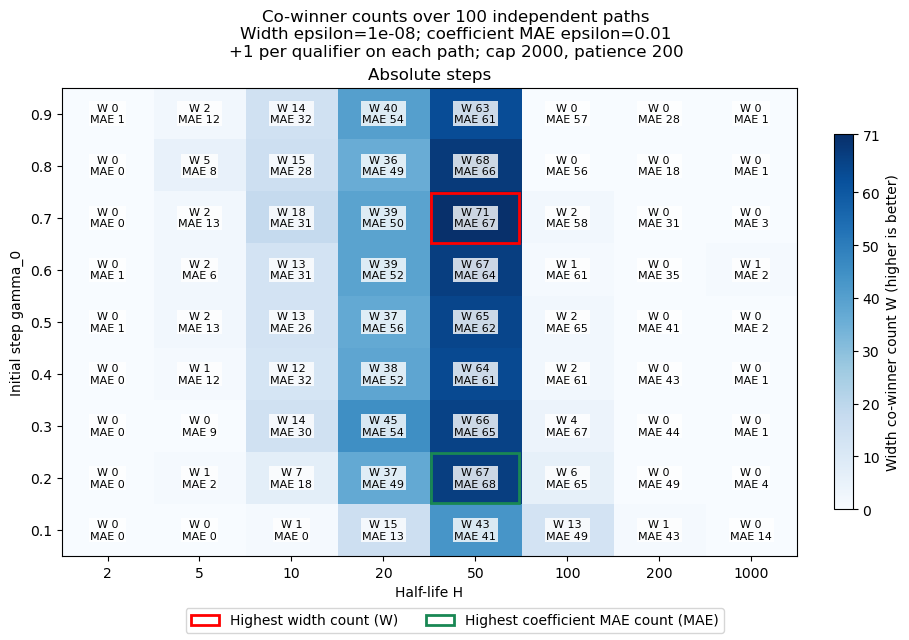

In [51]:
epsilon_win_figure_stem = (
    f"07_epsilon_win_counts_width_{epsilon_win_tolerance:g}_coefficient_mae_{coefficient_epsilon_win_tolerance:g}"
)
fig, epsilon_win_matrices = plot_tuning_matrices(
    combined_win_ranking, scale_grid, half_life_grid, metric="wins", maximize=True, precision=0,
    secondary_metric="coefficient_wins",
    title=(f"Co-winner counts over {number_of_realizations} independent paths\n"
           f"Width epsilon={epsilon_win_tolerance:g}; coefficient MAE epsilon={coefficient_epsilon_win_tolerance:g}\n"
           f"+1 per qualifier on each path; cap {max_iterations}, patience {patience}"),
    colorbar_label="Width co-winner count W (higher is better)",
    filename=epsilon_win_figure_stem, pdf_directory=PDF_DIR, image_directory=IMAGE_DIR,
)
coefficient_win_matrices = {
    rule: combined_win_ranking.loc[combined_win_ranking["step_rule"] == rule].pivot(
        index="step_value", columns="half_life", values="coefficient_wins",
    ).reindex(index=scale_grid, columns=half_life_grid)
    for rule in ("absolute",)
}
plt.show()
plt.close(fig)


## Experiment 3: 100 Jones-sampled AR(3) models, one fixed starting direction

For each model, draw a fresh coefficient vector with the existing [Jones sampler](../ar_tools/functions.py), then simulate one independent length-$T=500$ path with $U(-1,1)$ innovations after the same 2,000-observation burn-in. Jones's construction samples coefficients uniformly from the causal AR region through independent beta-distributed partial autocorrelations and a recursive transformation. [Jones (1987), pp. 134–138](https://doi.org/10.2307/2347544).

Use **the common `initial_direction` from the shared setup**, one start per descent, the same scale and half-life grids, **2,000 maximum iterations and patience 200**. Each model's one fixed point cloud is shared by all absolute-step candidates. Coefficient and innovation draws use separate seeded streams. Record each draw's coefficients, partial autocorrelations, companion spectral radius and seeds. The Jones draws are retained without a spectral-radius cutoff.

Select configurations by the **same absolute-gap co-winner rule**: award +1 to every achieved minimum width at most that model's best achieved width plus `epsilon_win_tolerance` (default $10^{-8}$). [Shared tuning and counting implementation](../ar_tools/tuning.py), `tune_jones_ar_realizations` and `summarize_configuration_wins`.

The variables below use the `jones_` prefix. Earlier experiment results remain available. Only PDF/PNG matrices are exported; all sampled models and numerical results remain in the notebook. No iteration plots or JSON/CSV data exports are generated.

Each progress line also reports the theoretical **population** minimum $2/\sqrt{1+\|\phi\|^2}$ and the signed empirical-minus-population gap. The final width diagnostic compares this reference with a known feasible direction on the same sample. These benchmarks do not enter the tuning score. [Thesis, Proposition `prop:minimum_width`](../../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex).

In [52]:
number_of_coefficient_realizations = 100  # CHANGE THIS: number of distinct Jones-sampled AR(3) models.
jones_coefficient_seed = 20261023
jones_process_seed = 20261024

jones_configuration = {
    "experiment": "jones_ar3_tuning", "T": int(T), "p": int(p),
    "replications": int(number_of_coefficient_realizations),
    "coefficient_sampling": "Jones1987_uniform_causal_AR3",
    "coefficient_seed": int(jones_coefficient_seed), "process_seed": int(jones_process_seed),
    "innovation_distribution": "Uniform(-1,1)", "burnin": int(burnin),
    "initial_direction": initial_direction.tolist(), "starts": 1, "optimizer_seed": int(optimizer_seed),
    "max_iterations": int(max_iterations), "patience": int(patience),
    "improvement_tolerance": float(improvement_tolerance),
    "scale_grid": scale_grid.tolist(), "half_life_grid": half_life_grid.tolist(),
    "step_rules": ["absolute"],
    "epsilon": float(epsilon_win_tolerance), "selection": "most_absolute_gap_co_winner_credits",
    "source_sha256": hashlib.sha256(b"".join(
        (AR_CODE_DIR / "ar_tools" / name).read_bytes()
        for name in ["functions.py", "innovations.py", "descent.py", "tuning.py", "tuning_plots.py", "coefficient_errors.py"]
    )).hexdigest(),
}
jones_run_id = hashlib.sha256(repr(sorted(jones_configuration.items())).encode()).hexdigest()[:16]
JONES_PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / f"jones_{jones_run_id}"
JONES_IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / f"jones_{jones_run_id}"
for directory in (JONES_PDF_DIR, JONES_IMAGE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print(f"Experiment 3: {number_of_coefficient_realizations} Jones AR(3) models, T={T}; cap {max_iterations}, patience {patience}.")
print(f"The same fixed u_0 for every candidate and model: {initial_direction}")

Experiment 3: 100 Jones AR(3) models, T=500; cap 2000, patience 200.
The same fixed u_0 for every candidate and model: [ 0.0469043  -0.81156153  0.31282302  0.49123275]


In [53]:
jones_experiment = tune_jones_ar_realizations(
    T, initial_direction, scale_grid, half_life_grid,
    replications=number_of_coefficient_realizations,
    coefficient_seed=jones_coefficient_seed, process_seed=jones_process_seed,
    burnin=burnin, iterations=max_iterations, patience=patience,
    improvement_tolerance=improvement_tolerance, optimizer_seed=optimizer_seed, progress=True, summarize=False,
)
jones_results = pd.DataFrame(jones_experiment["results"])
jones_cases = pd.DataFrame(jones_experiment["cases"])
np.testing.assert_allclose(jones_experiment["initial_direction"], initial_direction, atol=1e-15, rtol=0)
assert len(jones_cases) == number_of_coefficient_realizations
assert len(jones_results) == number_of_coefficient_realizations * len(scale_grid) * len(half_life_grid)
assert jones_results["total_evaluations"].between(1, max_iterations).all()
assert jones_results["selected_start"].eq(1).all()
assert jones_cases["coefficient_seed"].is_unique and jones_cases["process_seed"].is_unique
assert jones_cases[["phi_1", "phi_2", "phi_3"]].drop_duplicates().shape[0] == number_of_coefficient_realizations
assert jones_cases["spectral_radius"].between(0, 1, inclusive="left").all()
print(f"Completed {len(jones_cases)} distinct models and {len(jones_results)} paired candidate runs.")


Path 1/100, T=500: best achieved width=0.9943046919, population min=0.9997416721, empirical-population gap=-0.0054369802, 72 absolute schedules; 1.0s
Path 2/100, T=500: best achieved width=1.3146471407, population min=1.3221974789, empirical-population gap=-0.0075503381, 72 absolute schedules; 1.0s
Path 3/100, T=500: best achieved width=1.2281505150, population min=1.2728269262, empirical-population gap=-0.0446764112, 72 absolute schedules; 0.9s
Path 4/100, T=500: best achieved width=0.9717235442, population min=1.0059953689, empirical-population gap=-0.0342718247, 72 absolute schedules; 0.7s
Path 5/100, T=500: best achieved width=0.6635217138, population min=0.6690338627, empirical-population gap=-0.0055121489, 72 absolute schedules; 0.7s
Path 6/100, T=500: best achieved width=1.4382801546, population min=1.4681855298, empirical-population gap=-0.0299053752, 72 absolute schedules; 0.8s
Path 7/100, T=500: best achieved width=1.8430135441, population min=1.8539449890, empirical-populati

In [54]:
jones_model_columns = [
    "replication", "phi_1", "phi_2", "phi_3", "pacf_1", "pacf_2", "pacf_3",
    "spectral_radius", "coefficient_seed", "process_seed", "grid_best_width",
    "population_minimum_width", "grid_population_width_gap",
    "empirical_true_direction_width", "grid_empirical_true_direction_gap",
]
print("All sampled models and seeds:")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.precision", 8):
    display(jones_cases[jones_model_columns])
print(f"Companion spectral-radius range: [{jones_cases['spectral_radius'].min():.8f}, "
      f"{jones_cases['spectral_radius'].max():.8f}].")

All sampled models and seeds:


,replication,phi_1,phi_2,phi_3,pacf_1,pacf_2,pacf_3,spectral_radius,coefficient_seed,process_seed,grid_best_width,population_minimum_width,grid_population_width_gap,empirical_true_direction_width,grid_empirical_true_direction_gap
0,1,1.35177242,-0.93644824,0.54575035,0.93321038,-0.28301092,0.54575035,0.96700120,16288181045755222347,10828296777479882745,0.99430469,0.99974167,-0.00543698,0.99941216,-0.00510747
1,2,-0.51381023,0.85629840,0.53926963,-0.40035132,0.81673115,0.53926963,0.96105313,11105578151043523248,12800449988372288735,1.31464714,1.32219748,-0.00755034,1.31832403,-0.00367689
2,3,0.77354339,-0.88980437,0.28085567,0.32857282,-0.73014402,0.28085567,0.86038735,10273860152015697191,10831720995082206158,1.22815052,1.27282693,-0.04467641,1.26717011,-0.03901959
3,4,1.35689922,-0.96486037,0.42465741,0.78387565,-0.47414804,0.42465741,0.81263086,6366326135738863003,7601784367034788820,0.97172354,1.00599537,-0.03427182,0.99729807,-0.02557453
4,5,-1.95035008,-1.87431396,-0.78708720,-0.66012720,-0.89152159,-0.78708720,0.97114441,7551298518433996483,8340308198013301003,0.66352171,0.66903386,-0.00551215,0.66656752,-0.00304581
5,6,0.89812834,-0.20595791,-0.08127461,0.71903908,-0.28080784,-0.08127461,0.64671927,11591331125286168226,12385543695779430734,1.43828015,1.46818553,-0.02990538,1.46534040,-0.02706025
6,7,0.23994370,0.25585116,-0.20182893,0.25045908,0.21623176,-0.20182893,0.64399523,290960773894637450,13964900212507695027,1.84301354,1.85394499,-0.01093144,1.84667460,-0.00366105
7,8,0.24301261,0.53968770,-0.45344962,-0.00468243,0.54066299,-0.45344962,0.90568494,16971434785173947726,1306502758028956009,1.59371816,1.60337216,-0.00965400,1.59728726,-0.00356910
8,9,-0.50776003,0.69680754,0.66191736,-0.23132148,0.64199069,0.66191736,0.95276611,6561579481862075310,16276280573437201634,1.32851127,1.35410651,-0.02559524,1.34723476,-0.01872349
9,10,0.65218559,0.50724698,-0.79497548,0.65641183,-0.03050039,-0.79497548,0.94082046,11743614143701613157,17073338895397600117,1.29844404,1.31458618,-0.01614214,1.30870869,-0.01026465


Companion spectral-radius range: [0.41315948, 0.99908161].


In [55]:
jones_win_experiment = summarize_configuration_wins(
    jones_results.to_dict("records"), score_key="minimum_width", epsilon=epsilon_win_tolerance,
)
jones_win_step_ranges = jones_results.groupby("candidate_id", as_index=False).agg(
    gamma0_min=("gamma0", "min"), gamma0_max=("gamma0", "max"),
)
jones_win_ranking = pd.DataFrame(jones_win_experiment["ranking"]).rename(
    columns={"rank": "win_rank"},
).merge(jones_win_step_ranges, on="candidate_id", validate="one_to_one").sort_values("win_rank")
jones_win_leaders = jones_win_ranking.loc[
    jones_win_ranking["wins"] == jones_win_ranking["wins"].max()
].copy()
jones_win_winners = pd.DataFrame(jones_win_experiment["winners"])
assert jones_win_experiment["cases"] == number_of_coefficient_realizations
assert jones_win_ranking["wins"].between(0, number_of_coefficient_realizations).all()
assert jones_win_ranking["wins"].sum() == len(jones_win_winners) == jones_win_experiment["total_points"]
assert not jones_win_winners.duplicated(["replication", "T", "candidate_id"]).any()
assert (jones_win_winners["winning_score"] <= jones_win_winners["winning_threshold"]).all()
jones_win_columns = [
    "win_rank", "step_rule", "step_value", "half_life", "beta",
    "wins", "win_rate", "mean_evaluations",
]
print(f"Experiment 3 selection: +1 to every configuration within {epsilon_win_tolerance:g} of each model's best achieved width.")
with pd.option_context("display.max_columns", None, "display.precision", 10):
    display(jones_win_ranking[jones_win_columns].head(15))
    print("All configurations with the highest win count:")
    display(jones_win_leaders[jones_win_columns])
print(f"{jones_win_experiment['cases']} models; {jones_win_experiment['total_points']} full +1 credits; "
      f"{jones_win_experiment['tied_cases']} models with multiple co-winners.")

Experiment 3 selection: +1 to every configuration within 1e-08 of each model's best achieved width.


,win_rank,step_rule,step_value,half_life,beta,wins,win_rate,mean_evaluations
0,1,absolute,0.3,50.0,0.9862327045,43,0.43,1698.40
1,2,absolute,0.5,50.0,0.9862327045,43,0.43,1730.66
2,3,absolute,0.7,50.0,0.9862327045,41,0.41,1650.16
3,4,absolute,0.1,50.0,0.9862327045,40,0.40,1832.07
4,5,absolute,0.4,50.0,0.9862327045,40,0.40,1744.64
5,6,absolute,0.8,50.0,0.9862327045,39,0.39,1614.23
6,7,absolute,0.9,50.0,0.9862327045,39,0.39,1566.04
7,8,absolute,0.6,50.0,0.9862327045,38,0.38,1639.70
8,9,absolute,0.2,50.0,0.9862327045,37,0.37,1741.96
9,10,absolute,0.3,20.0,0.9659363289,24,0.24,1221.55


All configurations with the highest win count:


,win_rank,step_rule,step_value,half_life,beta,wins,win_rate,mean_evaluations
0,1,absolute,0.3,50.0,0.9862327045,43,0.43,1698.40
1,2,absolute,0.5,50.0,0.9862327045,43,0.43,1730.66


100 models; 706 full +1 credits; 54 models with multiple co-winners.


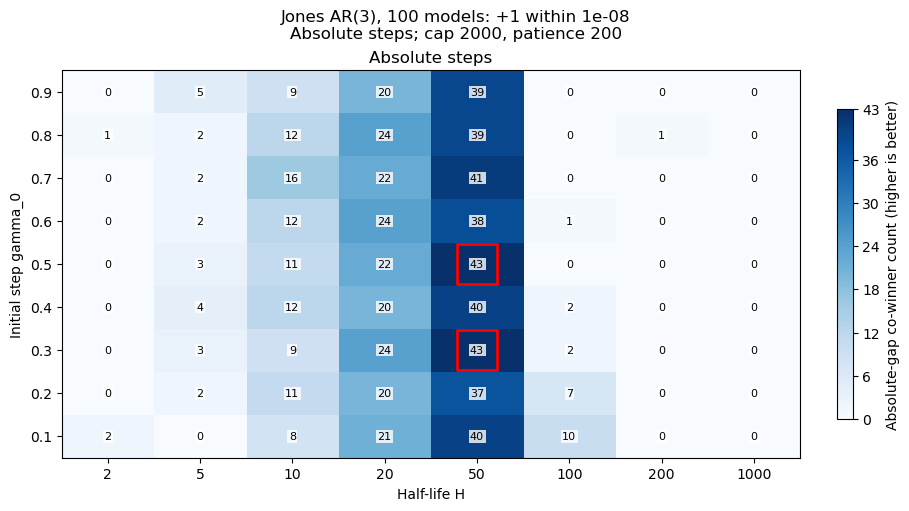

In [56]:
jones_win_figure_stem = f"02_jones_win_counts_eps_{epsilon_win_tolerance:g}"
fig, jones_win_matrices = plot_tuning_matrices(
    jones_win_ranking, scale_grid, half_life_grid, metric="wins", maximize=True, precision=0,
    title=(f"Jones AR(3), {number_of_coefficient_realizations} models: +1 within {epsilon_win_tolerance:g}\n"
           f"Absolute steps; cap {max_iterations}, patience {patience}"),
    colorbar_label="Absolute-gap co-winner count (higher is better)",
    filename=jones_win_figure_stem, pdf_directory=JONES_PDF_DIR, image_directory=JONES_IMAGE_DIR,
)
plt.show()
plt.close(fig)

In [57]:
print("Experiment 3 winners under the absolute-gap win-count rule:")
for choice in jones_win_leaders.to_dict("records"):
    print(f"{choice['step_rule']}: scale={choice['step_value']:g}, H={choice['half_life']:g}, "
          f"beta={choice['beta']:.12g}; {int(choice['wins'])}/{number_of_coefficient_realizations} model wins.")
    print(f"Actual gamma0 range across models: [{choice['gamma0_min']:.12g}, {choice['gamma0_max']:.12g}].")
print(f"One fixed u_0 throughout: {initial_direction}")
print(f"PDF matrices: {JONES_PDF_DIR}")

Experiment 3 winners under the absolute-gap win-count rule:
absolute: scale=0.3, H=50, beta=0.986232704493; 43/100 model wins.
Actual gamma0 range across models: [0.3, 0.3].
absolute: scale=0.5, H=50, beta=0.986232704493; 43/100 model wins.
Actual gamma0 range across models: [0.5, 0.5].
One fixed u_0 throughout: [ 0.0469043  -0.81156153  0.31282302  0.49123275]
PDF matrices: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar_tuning_experiments/jones_563c28d181a38b1a


## Experiment 3 repeated: stationarity check enabled

Repeat the preceding experiment on **the same Jones-sampled models and the same independent realization for each model**, using the same coefficient/process seeds, initial direction, tuning grid and width co-winner tolerance. The only optimizer change is **`stationarity_check=True`**. [Shared runner](../ar_tools/tuning.py), `tune_jones_ar_realizations`.

After the first `patience` evaluated directions of each attempt (200 by default), recover the coefficients from that attempt's **best-width direction** and check whether every companion eigenvalue has magnitude strictly below one. An undefined estimate or a failed check triggers a fresh random starting direction, a reset step schedule and a **fresh full iteration budget** (2,000 by default). Discard the failed attempt's best width. Repeat the checkpoint on each restarted attempt. A passing attempt continues without further checks or a final stationarity filter. [Optimizer checkpoint and restart rule](../ar_tools/descent.py), `projected_subgradient_empirical_width`.

The first starting direction is common to all configurations; restart directions are generated reproducibly by the optimizer's seeded stream. Allow at most `jones_stationarity_max_restarts` fresh starts per configuration (default 100). If this limit is exhausted, record the configuration/model run as failed with an undefined achieved width and **no win credit**. Report failures explicitly; a model on which every configuration fails awards no points and remains in the denominator. Evaluation totals include all discarded attempts. This can use more total evaluations than the original experiment.

Select configurations using the same full +1 width co-winner rule and retain all final ties. Variables and PDF/PNG exports use a separate `jones_stationarity_` prefix. The original Experiment 3 results remain available.


In [58]:
# Reuse the preceding experiment's model count and random streams.
jones_stationarity_coefficient_seed = jones_coefficient_seed
jones_stationarity_process_seed = jones_process_seed
jones_stationarity_check = True
jones_stationarity_max_restarts = 100

jones_stationarity_configuration = {
    "experiment": "jones_stationarity_ar3_tuning", "T": int(T), "p": int(p),
    "replications": int(number_of_coefficient_realizations),
    "coefficient_sampling": "Jones1987_uniform_causal_AR3",
    "coefficient_seed": int(jones_stationarity_coefficient_seed), "process_seed": int(jones_stationarity_process_seed),
    "innovation_distribution": "Uniform(-1,1)", "burnin": int(burnin),
    "initial_direction": initial_direction.tolist(), "starts": 1, "optimizer_seed": int(optimizer_seed),
    "max_iterations": int(max_iterations), "patience": int(patience),
    "improvement_tolerance": float(improvement_tolerance),
    "scale_grid": scale_grid.tolist(), "half_life_grid": half_life_grid.tolist(),
    "step_rules": ["absolute"],
    "stationarity_check": bool(jones_stationarity_check),
    "max_restarts": int(jones_stationarity_max_restarts),
    "iteration_budget": "fresh_full_budget_per_attempt",
    "epsilon": float(epsilon_win_tolerance), "selection": "most_absolute_gap_co_winner_credits",
    "source_sha256": hashlib.sha256(b"".join(
        (AR_CODE_DIR / "ar_tools" / name).read_bytes()
        for name in ["functions.py", "innovations.py", "descent.py", "tuning.py", "tuning_plots.py", "coefficient_errors.py"]
    )).hexdigest(),
}
jones_stationarity_run_id = hashlib.sha256(repr(sorted(jones_stationarity_configuration.items())).encode()).hexdigest()[:16]
JONES_STATIONARITY_PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / f"jones_stationarity_{jones_stationarity_run_id}"
JONES_STATIONARITY_IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / f"jones_stationarity_{jones_stationarity_run_id}"
for directory in (JONES_STATIONARITY_PDF_DIR, JONES_STATIONARITY_IMAGE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print(f"Experiment 3 with stationarity check: {number_of_coefficient_realizations} Jones AR(3) models, T={T}; cap {max_iterations}, patience {patience}.")
print(f"Common first starting direction for every candidate and model: {initial_direction}")
print(f"Stationarity check: {jones_stationarity_check}; checkpoint after {patience} evaluations per attempt; "
      f"up to {jones_stationarity_max_restarts} restarts per configuration.")


Experiment 3 with stationarity check: 100 Jones AR(3) models, T=500; cap 2000, patience 200.
Common first starting direction for every candidate and model: [ 0.0469043  -0.81156153  0.31282302  0.49123275]
Stationarity check: True; checkpoint after 200 evaluations per attempt; up to 100 restarts per configuration.


In [59]:
jones_stationarity_experiment = tune_jones_ar_realizations(
    T, initial_direction, scale_grid, half_life_grid,
    replications=number_of_coefficient_realizations,
    coefficient_seed=jones_stationarity_coefficient_seed, process_seed=jones_stationarity_process_seed,
    burnin=burnin, iterations=max_iterations, patience=patience,
    improvement_tolerance=improvement_tolerance, optimizer_seed=optimizer_seed, progress=True, summarize=False,
    stationarity_check=jones_stationarity_check, max_restarts=jones_stationarity_max_restarts,
)
jones_stationarity_results = pd.DataFrame(jones_stationarity_experiment["results"])
jones_stationarity_cases = pd.DataFrame(jones_stationarity_experiment["cases"])
np.testing.assert_allclose(jones_stationarity_experiment["initial_direction"], initial_direction, atol=1e-15, rtol=0)
assert len(jones_stationarity_cases) == number_of_coefficient_realizations
assert len(jones_stationarity_results) == number_of_coefficient_realizations * len(scale_grid) * len(half_life_grid)
assert jones_stationarity_results["stationarity_check"].all()
assert jones_stationarity_results["stationarity_check_passed"].eq(
    ~jones_stationarity_results["restart_limit_reached"]
).all()
assert np.isfinite(jones_stationarity_results["minimum_width"]).eq(
    jones_stationarity_results["stationarity_check_passed"]
).all()
assert jones_stationarity_results["restart_count"].between(0, jones_stationarity_max_restarts).all()
assert jones_stationarity_results["attempt_count"].eq(jones_stationarity_results["restart_count"] + 1).all()
assert jones_stationarity_results["final_evaluations"].between(patience, max_iterations).all()
assert jones_stationarity_results.loc[
    jones_stationarity_results["stationarity_check_passed"], "checkpoint_spectral_radius"
].between(0, 1, inclusive="left").all()
np.testing.assert_array_equal(
    jones_stationarity_results["total_evaluations"],
    jones_stationarity_results["restart_count"] * patience + jones_stationarity_results["final_evaluations"],
)
assert jones_stationarity_results["selected_start"].eq(1).all()
assert jones_stationarity_cases["coefficient_seed"].is_unique and jones_stationarity_cases["process_seed"].is_unique
assert jones_stationarity_cases[["phi_1", "phi_2", "phi_3"]].drop_duplicates().shape[0] == number_of_coefficient_realizations
assert jones_stationarity_cases["spectral_radius"].between(0, 1, inclusive="left").all()
print(f"Completed {len(jones_stationarity_cases)} distinct models and {len(jones_stationarity_results)} paired candidate runs.")

# Verify that the repeat uses exactly the original model/path inputs.
jones_stationarity_pairing_columns = [
    "replication", "T", "coefficient_seed", "process_seed", "phi_1", "phi_2", "phi_3",
    "pacf_1", "pacf_2", "pacf_3", "spectral_radius",
    "population_minimum_width", "empirical_true_direction_width",
]
pd.testing.assert_frame_equal(
    jones_cases[jones_stationarity_pairing_columns].reset_index(drop=True),
    jones_stationarity_cases[jones_stationarity_pairing_columns].reset_index(drop=True),
)
print(f"Restarted runs: {int(jones_stationarity_results['restart_count'].gt(0).sum())}/"
      f"{len(jones_stationarity_results)}; total restarts: {int(jones_stationarity_results['restart_count'].sum())}.")
print(f"Total evaluated directions, including discarded attempts: "
      f"{int(jones_stationarity_results['total_evaluations'].sum()):,}.")

print(f"Runs that exhausted the restart limit (no width win credit): "
      f"{int(jones_stationarity_results['restart_limit_reached'].sum())}/{len(jones_stationarity_results)}.")


Path 1/100, T=500: best achieved width=0.9943344938, population min=0.9997416721, empirical-population gap=-0.0054071783, 72 absolute schedules; 317 restarts; 0 failed runs; 2.0s
Path 2/100, T=500: best achieved width=1.3146525433, population min=1.3221974789, empirical-population gap=-0.0075449355, 72 absolute schedules; 118 restarts; 0 failed runs; 1.1s
Path 3/100, T=500: best achieved width=1.2281505150, population min=1.2728269262, empirical-population gap=-0.0446764112, 72 absolute schedules; 21 restarts; 0 failed runs; 0.9s
Path 4/100, T=500: best achieved width=0.9716067099, population min=1.0059953689, empirical-population gap=-0.0343886591, 72 absolute schedules; 10 restarts; 0 failed runs; 0.7s
Path 5/100, T=500: best achieved width=0.6635217138, population min=0.6690338627, empirical-population gap=-0.0055121489, 72 absolute schedules; 99 restarts; 0 failed runs; 0.9s
Path 6/100, T=500: best achieved width=1.4477161019, population min=1.4681855298, empirical-population gap=-

In [60]:
jones_stationarity_model_columns = [
    "replication", "phi_1", "phi_2", "phi_3", "pacf_1", "pacf_2", "pacf_3",
    "spectral_radius", "coefficient_seed", "process_seed", "grid_best_width",
    "population_minimum_width", "grid_population_width_gap",
    "empirical_true_direction_width", "grid_empirical_true_direction_gap",
    "restart_count", "total_evaluations", "failed_runs",
]
print("All sampled models and seeds:")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.precision", 8):
    display(jones_stationarity_cases[jones_stationarity_model_columns])
print(f"Companion spectral-radius range: [{jones_stationarity_cases['spectral_radius'].min():.8f}, "
      f"{jones_stationarity_cases['spectral_radius'].max():.8f}].")

All sampled models and seeds:
Companion spectral-radius range: [0.41315948, 0.99908161].


,replication,phi_1,phi_2,phi_3,pacf_1,pacf_2,pacf_3,spectral_radius,coefficient_seed,process_seed,grid_best_width,population_minimum_width,grid_population_width_gap,empirical_true_direction_width,grid_empirical_true_direction_gap,restart_count,total_evaluations,failed_runs
0,1,1.35177242,-0.93644824,0.54575035,0.93321038,-0.28301092,0.54575035,0.96700120,16288181045755222347,10828296777479882745,0.99433449,0.99974167,-0.00540718,0.99941216,-0.00507766,317,106641,0
1,2,-0.51381023,0.85629840,0.53926963,-0.40035132,0.81673115,0.53926963,0.96105313,11105578151043523248,12800449988372288735,1.31465254,1.32219748,-0.00754494,1.31832403,-0.00367149,118,76345,0
2,3,0.77354339,-0.88980437,0.28085567,0.32857282,-0.73014402,0.28085567,0.86038735,10273860152015697191,10831720995082206158,1.22815052,1.27282693,-0.04467641,1.26717011,-0.03901959,21,69122,0
3,4,1.35689922,-0.96486037,0.42465741,0.78387565,-0.47414804,0.42465741,0.81263086,6366326135738863003,7601784367034788820,0.97160671,1.00599537,-0.03438866,0.99729807,-0.02569136,10,54964,0
4,5,-1.95035008,-1.87431396,-0.78708720,-0.66012720,-0.89152159,-0.78708720,0.97114441,7551298518433996483,8340308198013301003,0.66352171,0.66903386,-0.00551215,0.66656752,-0.00304581,99,69302,0
5,6,0.89812834,-0.20595791,-0.08127461,0.71903908,-0.28080784,-0.08127461,0.64671927,11591331125286168226,12385543695779430734,1.44771610,1.46818553,-0.02046943,1.46534040,-0.01762430,3880,805910,33
6,7,0.23994370,0.25585116,-0.20182893,0.25045908,0.21623176,-0.20182893,0.64399523,290960773894637450,13964900212507695027,1.84301354,1.85394499,-0.01093144,1.84667460,-0.00366105,136,95109,0
7,8,0.24301261,0.53968770,-0.45344962,-0.00468243,0.54066299,-0.45344962,0.90568494,16971434785173947726,1306502758028956009,1.59371692,1.60337216,-0.00965524,1.59728726,-0.00357034,18,64389,0
8,9,-0.50776003,0.69680754,0.66191736,-0.23132148,0.64199069,0.66191736,0.95276611,6561579481862075310,16276280573437201634,1.32851127,1.35410651,-0.02559524,1.34723476,-0.01872349,17,76988,0
9,10,0.65218559,0.50724698,-0.79497548,0.65641183,-0.03050039,-0.79497548,0.94082046,11743614143701613157,17073338895397600117,1.29844404,1.31458618,-0.01614214,1.30870869,-0.01026465,68,62352,0


In [61]:
jones_stationarity_win_experiment = summarize_configuration_wins(
    jones_stationarity_results.to_dict("records"), score_key="minimum_width", epsilon=epsilon_win_tolerance, allow_nonfinite=True,
)
jones_stationarity_win_step_ranges = jones_stationarity_results.groupby("candidate_id", as_index=False).agg(
    gamma0_min=("gamma0", "min"), gamma0_max=("gamma0", "max"),
    total_restarts=("restart_count", "sum"),
)
jones_stationarity_win_ranking = pd.DataFrame(jones_stationarity_win_experiment["ranking"]).rename(
    columns={"rank": "win_rank", "undefined_scores": "failed_runs"},
).merge(jones_stationarity_win_step_ranges, on="candidate_id", validate="one_to_one").sort_values("win_rank")
jones_stationarity_win_leaders = jones_stationarity_win_ranking.loc[
    jones_stationarity_win_ranking["wins"] == jones_stationarity_win_ranking["wins"].max()
].copy()
jones_stationarity_win_winners = pd.DataFrame(jones_stationarity_win_experiment["winners"])
assert jones_stationarity_win_experiment["cases"] == number_of_coefficient_realizations
assert jones_stationarity_win_ranking["wins"].between(0, number_of_coefficient_realizations).all()
assert jones_stationarity_win_ranking["wins"].sum() == len(jones_stationarity_win_winners) == jones_stationarity_win_experiment["total_points"]
assert not jones_stationarity_win_winners.duplicated(["replication", "T", "candidate_id"]).any()
assert (jones_stationarity_win_winners["winning_score"] <= jones_stationarity_win_winners["winning_threshold"]).all()
jones_stationarity_win_columns = [
    "win_rank", "step_rule", "step_value", "half_life", "beta",
    "wins", "win_rate", "mean_evaluations", "total_restarts", "failed_runs",
]
print(f"Experiment 3 with stationarity check selection: +1 to every configuration within {epsilon_win_tolerance:g} of each model's best achieved width.")
with pd.option_context("display.max_columns", None, "display.precision", 10):
    display(jones_stationarity_win_ranking[jones_stationarity_win_columns].head(15))
    print("All configurations with the highest win count:")
    display(jones_stationarity_win_leaders[jones_stationarity_win_columns])
print(f"{jones_stationarity_win_experiment['cases']} models; {jones_stationarity_win_experiment['total_points']} full +1 credits; "
      f"{jones_stationarity_win_experiment['tied_cases']} models with multiple co-winners.")
assert jones_stationarity_win_winners["stationarity_check_passed"].all()
print(f"Models with no successful configuration: {jones_stationarity_win_experiment['undefined_cases']} "
      f"(retained in the denominator).")


Experiment 3 with stationarity check selection: +1 to every configuration within 1e-08 of each model's best achieved width.
All configurations with the highest win count:
100 models; 840 full +1 credits; 53 models with multiple co-winners.
Models with no successful configuration: 0 (retained in the denominator).


,win_rank,step_rule,step_value,half_life,beta,wins,win_rate,mean_evaluations,total_restarts,failed_runs
0,1,absolute,0.2,50.0,0.9862327045,51,0.51,3726.93,1064,6
1,2,absolute,0.1,50.0,0.9862327045,49,0.49,2717.94,485,3
2,3,absolute,0.3,50.0,0.9862327045,49,0.49,3769.73,1108,8
3,4,absolute,0.4,50.0,0.9862327045,48,0.48,3877.85,1154,6
4,5,absolute,0.6,50.0,0.9862327045,46,0.46,3504.91,977,6
5,6,absolute,0.5,50.0,0.9862327045,42,0.42,3691.55,1111,8
6,7,absolute,0.7,50.0,0.9862327045,39,0.39,3705.04,1169,7
7,8,absolute,0.9,50.0,0.9862327045,39,0.39,3240.63,895,5
8,9,absolute,0.8,50.0,0.9862327045,37,0.37,2928.06,751,3
9,10,absolute,0.3,20.0,0.9659363289,31,0.31,3225.35,1027,5


,win_rank,step_rule,step_value,half_life,beta,wins,win_rate,mean_evaluations,total_restarts,failed_runs
0,1,absolute,0.2,50.0,0.9862327045,51,0.51,3726.93,1064,6


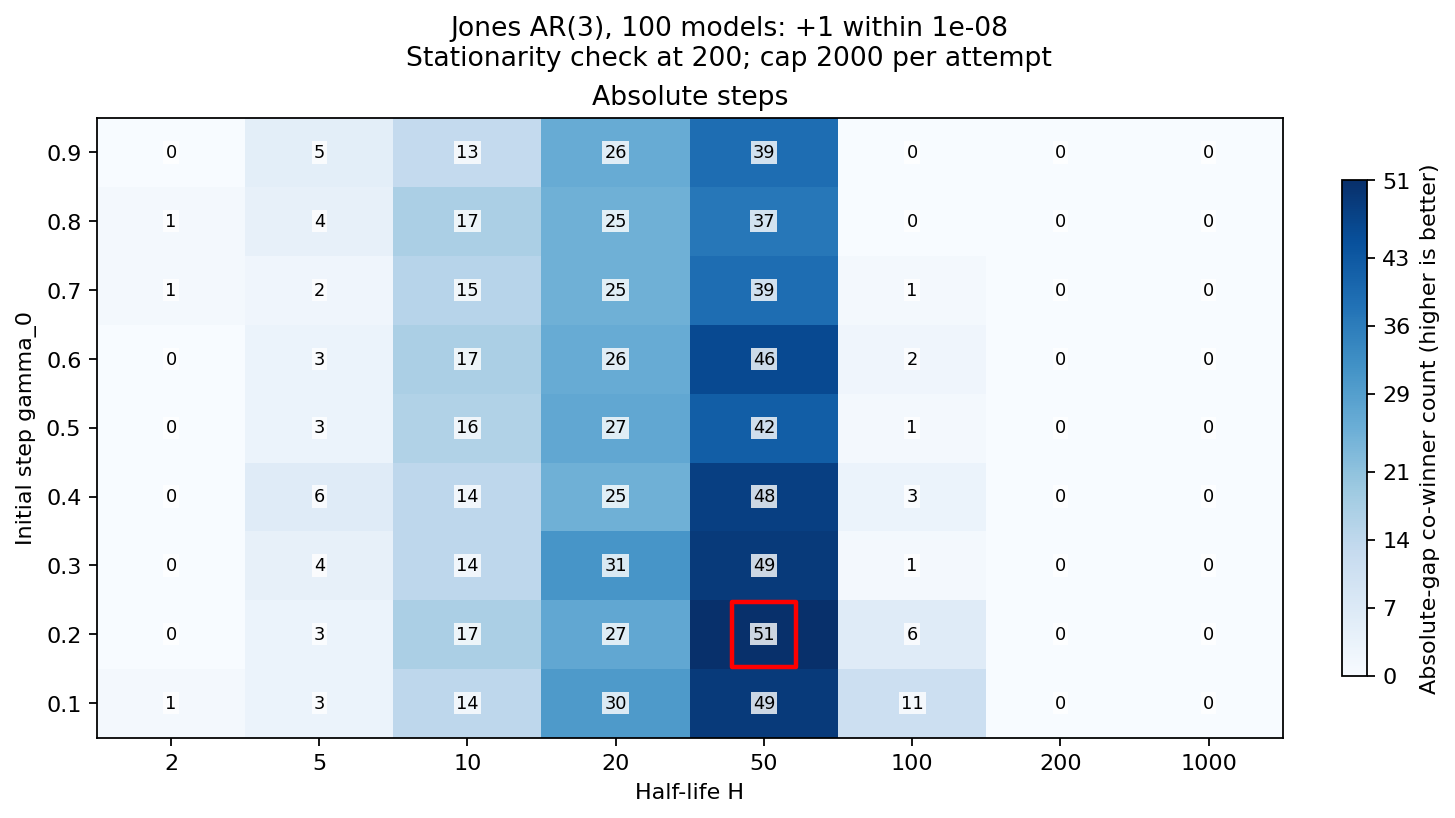

In [62]:
jones_stationarity_win_figure_stem = f"03_jones_stationarity_win_counts_eps_{epsilon_win_tolerance:g}"
fig, jones_stationarity_win_matrices = plot_tuning_matrices(
    jones_stationarity_win_ranking, scale_grid, half_life_grid, metric="wins", maximize=True, precision=0,
    title=(f"Jones AR(3), {number_of_coefficient_realizations} models: +1 within {epsilon_win_tolerance:g}\n"
           f"Stationarity check at {patience}; cap {max_iterations} per attempt"),
    colorbar_label="Absolute-gap co-winner count (higher is better)",
    filename=jones_stationarity_win_figure_stem, pdf_directory=JONES_STATIONARITY_PDF_DIR, image_directory=JONES_STATIONARITY_IMAGE_DIR,
)
plt.show()
plt.close(fig)

In [63]:
print("Experiment 3 with stationarity check: winners under the absolute-gap win-count rule:")
for choice in jones_stationarity_win_leaders.to_dict("records"):
    print(f"{choice['step_rule']}: scale={choice['step_value']:g}, H={choice['half_life']:g}, "
          f"beta={choice['beta']:.12g}; {int(choice['wins'])}/{number_of_coefficient_realizations} model wins.")
    print(f"Restarts across all models: {int(choice['total_restarts'])}; "
          f"failed runs: {int(choice['failed_runs'])}.")
    print(f"Actual gamma0 range across models: [{choice['gamma0_min']:.12g}, {choice['gamma0_max']:.12g}].")
print(f"Common first starting direction: {initial_direction}")
print(f"PDF matrices: {JONES_STATIONARITY_PDF_DIR}")

Experiment 3 with stationarity check: winners under the absolute-gap win-count rule:
absolute: scale=0.2, H=50, beta=0.986232704493; 51/100 model wins.
Restarts across all models: 1064; failed runs: 6.
Actual gamma0 range across models: [0.2, 0.2].
Common first starting direction: [ 0.0469043  -0.81156153  0.31282302  0.49123275]
PDF matrices: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar_tuning_experiments/jones_stationarity_1e98842053ef65a2


## Model 6: 100 independent realizations, fixed coefficients

Repeat the design of Experiment 2 for Jones model 6, using its **full-precision coefficients** from Experiment 3:
$$\phi=(0.8981283425999981,-0.2059579137943896,-0.08127461108863643).$$
Generate 100 new, independent length-$T=500$ realizations with uniform innovations on $[-1,1]$ and the same 2,000-observation burn-in. The fresh `model6_process_seed` selects a new innovation stream. Every configuration on a given path sees the same cloud and the common first starting direction. [Shared fixed-coefficient runner](../ar_tools/tuning.py), `tune_fixed_ar_realizations`.

Use the same 72 absolute-step configurations, maximum evaluations **per attempt**, patience and win tolerances as above. **Enable the existing stationarity check:** test the best-width direction after 200 evaluations of each attempt; restart with a fresh direction, step schedule and full budget when it fails. A passed attempt receives no later or final stationarity check. Allow up to 100 restarts; an exhausted fit receives no width or coefficient-error credit. All 100 paths remain in the denominators. [Optimizer](../ar_tools/descent.py), `projected_subgradient_empirical_width`.

The primary choice is every configuration with the highest width co-winner count (absolute tolerance $10^{-8}$). Also show the separate coefficient-MAE co-winner counter with tolerance $10^{-2}$, as in Experiment 2. The combined matrix uses red boxes for width leaders and green boxes for coefficient-error leaders. Report raw coefficient L1 error separately; L1 is three times the per-coefficient MAE for this AR(3) model. Means of coefficient errors use only finite returned estimates; failure counts remain explicit. Mean descent attempts include the initial attempt, restarts and exhausted fits.

The new variables and PDF/PNG exports use a `model6_` prefix. Independent paths may be processed in parallel (`model6_n_jobs`); the seeds and mathematical settings do not depend on the worker count. Earlier experiment results remain available.


In [64]:
# Refresh the fixed-path runner when continuing in an already-open kernel.
tuning_tools = importlib.reload(tuning_tools)
tune_fixed_ar_realizations = tuning_tools.tune_fixed_ar_realizations

model6_phi = np.array([
    0.8981283425999981, -0.2059579137943896, -0.08127461108863643,
], dtype=float)
model6_number_of_realizations = 100
model6_process_seed = 20261025
model6_stationarity_check = True
model6_max_restarts = 100
model6_n_jobs = 4
model6_stationary, model6_eigenvalues = is_stationary(model6_phi)
assert model6_stationary

model6_configuration = {
    "experiment": "model6_fixed_phi_realizations", "T": int(T), "p": int(p),
    "phi": model6_phi.tolist(), "replications": int(model6_number_of_realizations),
    "process_seed": int(model6_process_seed), "optimizer_seed": int(optimizer_seed),
    "initial_direction": initial_direction.tolist(), "starts": 1,
    "burnin": int(burnin), "innovation_distribution": "Uniform(-1,1)",
    "max_iterations_per_attempt": int(max_iterations), "patience": int(patience),
    "improvement_tolerance": float(improvement_tolerance),
    "stationarity_check": bool(model6_stationarity_check), "max_restarts": int(model6_max_restarts),
    "scale_grid": scale_grid.tolist(), "half_life_grid": half_life_grid.tolist(),
    "step_rules": ["absolute"], "epsilon_width": float(epsilon_win_tolerance),
    "epsilon_coefficient_mae": float(coefficient_epsilon_win_tolerance),
    "coefficient_error_metric": "mae_per_coefficient_v1", "parallel_workers": int(model6_n_jobs),
    "selection": "most_absolute_gap_co_winner_credits",
    "source_sha256": hashlib.sha256(b"".join(
        (AR_CODE_DIR / "ar_tools" / name).read_bytes()
        for name in ["functions.py", "innovations.py", "descent.py", "tuning.py", "tuning_plots.py", "coefficient_errors.py"]
    )).hexdigest(),
}
model6_run_id = hashlib.sha256(repr(sorted(model6_configuration.items())).encode()).hexdigest()[:16]
MODEL6_PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / f"model6_{model6_run_id}"
MODEL6_IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / f"model6_{model6_run_id}"
for directory in (MODEL6_PDF_DIR, MODEL6_IMAGE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print(f"Model 6: {model6_number_of_realizations} fresh paths, T={T}, process seed={model6_process_seed}.")
print(f"True coefficients: {model6_phi}; spectral radius={np.max(np.abs(model6_eigenvalues)):.8f}.")
print(f"Stationarity check={model6_stationarity_check}; checkpoint={patience}; "
      f"cap per attempt={max_iterations}; max restarts={model6_max_restarts}.")
print(f"Common first starting direction: {initial_direction}")


Model 6: 100 fresh paths, T=500, process seed=20261025.
True coefficients: [ 0.89812834 -0.20595791 -0.08127461]; spectral radius=0.64671927.
Stationarity check=True; checkpoint=200; cap per attempt=2000; max restarts=100.
Common first starting direction: [ 0.0469043  -0.81156153  0.31282302  0.49123275]


In [65]:
model6_experiment = tune_fixed_ar_realizations(
    model6_phi, T, initial_direction, scale_grid, half_life_grid,
    replications=model6_number_of_realizations, process_seed=model6_process_seed,
    burnin=burnin, iterations=max_iterations, patience=patience,
    improvement_tolerance=improvement_tolerance, optimizer_seed=optimizer_seed,
    stationarity_check=model6_stationarity_check, max_restarts=model6_max_restarts,
    n_jobs=model6_n_jobs, progress=True, summarize=False,
)
model6_results = pd.DataFrame(model6_experiment["results"])
model6_cases = pd.DataFrame(model6_experiment["cases"])
np.testing.assert_allclose(model6_experiment["initial_direction"], initial_direction, atol=1e-15, rtol=0)
assert len(model6_cases) == model6_number_of_realizations
assert len(model6_results) == model6_number_of_realizations * len(scale_grid) * len(half_life_grid)
assert model6_cases["process_seed"].is_unique
assert model6_results["stationarity_check"].all()
assert model6_results["stationarity_check_passed"].eq(~model6_results["restart_limit_reached"]).all()
assert model6_results["minimum_width"].notna().eq(model6_results["stationarity_check_passed"]).all()
assert model6_results["attempt_count"].eq(model6_results["restart_count"] + 1).all()
assert model6_results["final_evaluations"].between(patience, max_iterations).all()
np.testing.assert_array_equal(
    model6_results["total_evaluations"],
    model6_results["restart_count"] * patience + model6_results["final_evaluations"],
)
np.testing.assert_array_equal(
    model6_cases[[f"phi_{j}" for j in range(1, p + 1)]].to_numpy(),
    np.broadcast_to(model6_phi, (model6_number_of_realizations, p)),
)
model6_case_columns = [
    "replication", "T", "process_seed", "grid_best_width",
    "estimated_phi_1", "estimated_phi_2", "estimated_phi_3", "coefficient_mae",
    "grid_winner_step_value", "grid_winner_half_life", "failed_runs", "restart_count", "total_evaluations",
]
print(f"Completed {len(model6_cases)} independent paths and {len(model6_results)} labeled runs.")
print(f"Exhausted fits: {int(model6_results['restart_limit_reached'].sum())}/{len(model6_results)}; "
      f"mean descent attempts: {model6_results['attempt_count'].mean():.4f}.")
with pd.option_context("display.max_columns", None, "display.precision", 8):
    display(model6_cases[model6_case_columns])


Path 1/100, T=500: best achieved width=1.4431465806; 72 absolute schedules; 3220 restarts; 24 failed runs; 17.7s
Path 2/100, T=500: best achieved width=1.4203896124; 72 absolute schedules; 3625 restarts; 28 failed runs; 20.7s
Path 3/100, T=500: best achieved width=1.4500592683; 72 absolute schedules; 3899 restarts; 31 failed runs; 22.3s
Path 4/100, T=500: best achieved width=1.4408938380; 72 absolute schedules; 4050 restarts; 31 failed runs; 23.3s
Path 5/100, T=500: best achieved width=1.4433150721; 72 absolute schedules; 3787 restarts; 25 failed runs; 20.0s
Path 6/100, T=500: best achieved width=1.4036461576; 72 absolute schedules; 2570 restarts; 18 failed runs; 13.7s
Path 7/100, T=500: best achieved width=1.4455208759; 72 absolute schedules; 3304 restarts; 18 failed runs; 16.9s
Path 8/100, T=500: best achieved width=1.4502237022; 72 absolute schedules; 2826 restarts; 20 failed runs; 14.9s
Path 9/100, T=500: best achieved width=1.4430077547; 72 absolute schedules; 2803 restarts; 19 fa

,replication,T,process_seed,grid_best_width,estimated_phi_1,estimated_phi_2,estimated_phi_3,coefficient_mae,grid_winner_step_value,grid_winner_half_life,failed_runs,restart_count,total_evaluations
0,1,500,8083915264688443014,1.44314658,0.90335543,-0.24079564,-0.06734377,0.01799855,0.1,100.0,24,3220,678027
1,2,500,13776714538193749647,1.42038961,10.63354609,-9.48715850,3.01809129,7.37199475,0.7,50.0,28,3625,757289
2,3,500,12669551669822253943,1.45005927,0.91996082,-0.23876869,-0.07660888,0.01976966,0.1,50.0,31,3899,808828
3,4,500,7457271299291520165,1.44089384,13.46301825,-13.85008530,4.75492131,10.34840440,0.9,100.0,31,4050,838251
4,5,500,8672165176477322054,1.44331507,0.92328357,-0.23477091,-0.06843409,0.02226958,0.1,100.0,25,3787,785340
...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,500,2313402763508178260,1.44630311,0.89980624,-0.22604224,-0.06626634,0.01225683,0.1,50.0,12,1923,440147
96,97,500,10529363353797100672,1.42828072,6.46735833,-6.34029696,2.46469583,4.74984649,0.9,100.0,14,2118,461958
97,98,500,16562086509166472581,1.42556354,6.67681011,-6.63748147,2.20622582,4.83256859,0.9,50.0,4,1856,425702
98,99,500,7304523101865620438,1.45158953,0.95507122,-0.26222076,-0.08447337,0.03880149,0.6,5.0,12,2033,442362


In [66]:
model6_width_win_experiment = summarize_configuration_wins(
    model6_results.to_dict("records"),
    score_key="minimum_width", epsilon=epsilon_win_tolerance, allow_nonfinite=True,
)
model6_width_win_step_ranges = model6_results.groupby("candidate_id", as_index=False).agg(
    gamma0_min=("gamma0", "min"), gamma0_max=("gamma0", "max"),
    mean_attempts=("attempt_count", "mean"), total_restarts=("restart_count", "sum"),
)
model6_width_win_ranking = pd.DataFrame(model6_width_win_experiment["ranking"]).rename(
    columns={"rank": "win_rank", "undefined_scores": "failed_runs"},
).merge(model6_width_win_step_ranges, on="candidate_id", validate="one_to_one").sort_values("win_rank")
model6_width_win_leaders = model6_width_win_ranking.loc[
    model6_width_win_ranking["wins"] == model6_width_win_ranking["wins"].max()
].copy()
model6_width_win_winners = pd.DataFrame(model6_width_win_experiment["winners"])
model6_width_win_cases = pd.DataFrame(model6_width_win_experiment["case_summaries"])
assert model6_width_win_experiment["epsilon"] == epsilon_win_tolerance
assert model6_width_win_experiment["cases"] == model6_number_of_realizations
assert model6_width_win_ranking["wins"].between(0, model6_number_of_realizations).all()
assert model6_width_win_ranking["wins"].sum() == len(model6_width_win_winners) == model6_width_win_experiment["total_points"]
assert model6_width_win_cases["co_winners"].sum() == len(model6_width_win_winners)
if not model6_width_win_winners.empty:
    assert not model6_width_win_winners.duplicated(["replication", "T", "candidate_id"]).any()
    assert (model6_width_win_winners["winning_score"] <= model6_width_win_winners["winning_threshold"]).all()
    assert model6_width_win_winners["stationarity_check_passed"].all()

model6_width_win_columns = [
    "win_rank", "step_rule", "step_value", "half_life", "beta",
    "wins", "win_rate", "failed_runs", "mean_attempts", "mean_evaluations",
]

print(f"Model 6: {model6_number_of_realizations} paths; cap {max_iterations} per attempt, patience {patience}.")
print(f"+1 to EVERY configuration with achieved width <= path minimum + {epsilon_win_tolerance:g}.")
with pd.option_context("display.max_columns", None, "display.precision", 10):
    display(model6_width_win_ranking[model6_width_win_columns].head(15))
    print("All configurations with the highest absolute-gap win count:")
    display(model6_width_win_leaders[model6_width_win_columns])
print(f"{model6_width_win_experiment['cases']} realizations; {model6_width_win_experiment['total_points']} full +1 credits; "
      f"{model6_width_win_experiment['tied_cases']} paths with multiple co-winners; "
      f"maximum {model6_width_win_experiment['maximum_co_winners']} co-winners on one path.")
for choice in model6_width_win_leaders.to_dict("records"):
    print(f"Absolute-gap win-count leader: {choice['step_rule']}, scale={choice['step_value']:g}, "
          f"H={choice['half_life']:g}, beta={choice['beta']:.12g}; "
          f"wins={int(choice['wins'])}/{model6_number_of_realizations}.")
print(f"Paths with no successful configuration: {model6_width_win_experiment['undefined_cases']} "
      f"(retained in the denominator).")


Model 6: 100 paths; cap 2000 per attempt, patience 200.
+1 to EVERY configuration with achieved width <= path minimum + 1e-08.
All configurations with the highest absolute-gap win count:
100 realizations; 183 full +1 credits; 24 paths with multiple co-winners; maximum 14 co-winners on one path.
Absolute-gap win-count leader: absolute, scale=0.1, H=50, beta=0.986232704493; wins=40/100.
Paths with no successful configuration: 0 (retained in the denominator).


,win_rank,step_rule,step_value,half_life,beta,wins,win_rate,failed_runs,mean_attempts,mean_evaluations
0,1,absolute,0.1,50.0,0.9862327045,40,0.40,5,17.67,5182.38
1,2,absolute,0.1,20.0,0.9659363289,10,0.10,0,5.20,2018.92
2,3,absolute,0.1,100.0,0.9930924954,10,0.10,47,56.61,12067.39
3,4,absolute,0.2,50.0,0.9862327045,10,0.10,72,80.94,16638.64
4,5,absolute,0.9,50.0,0.9862327045,8,0.08,74,86.87,17663.22
5,6,absolute,0.2,20.0,0.9659363289,7,0.07,0,22.21,5422.92
6,7,absolute,0.3,20.0,0.9659363289,7,0.07,26,49.08,10535.39
7,8,absolute,0.3,50.0,0.9862327045,7,0.07,88,93.28,18854.83
8,9,absolute,0.4,20.0,0.9659363289,6,0.06,48,67.06,13931.03
9,10,absolute,0.4,100.0,0.9930924954,6,0.06,45,60.24,12366.94


,win_rank,step_rule,step_value,half_life,beta,wins,win_rate,failed_runs,mean_attempts,mean_evaluations
0,1,absolute,0.1,50.0,0.9862327045,40,0.4,5,17.67,5182.38


In [67]:
# Recover coefficients from each configuration's recorded minimum-width direction.
model6_coefficient_diagnostics = model6_results.copy()
model6_directions = model6_results[[f"u_{j}" for j in range(p + 1)]].to_numpy(dtype=float)
model6_coefficients = np.full((len(model6_results), p), np.nan)
model6_coefficient_valid = (
    np.isfinite(model6_directions).all(axis=1) & (np.abs(model6_directions[:, 0]) > 1e-10)
)
with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
    np.divide(-model6_directions[:, 1:], model6_directions[:, :1],
              out=model6_coefficients, where=model6_coefficient_valid[:, None])
    model6_coefficient_errors = coefficient_mae(model6_coefficients, model6_phi)
model6_coefficient_valid &= (
    np.isfinite(model6_coefficients).all(axis=1) & np.isfinite(model6_coefficient_errors)
)
model6_coefficient_errors[~model6_coefficient_valid] = np.nan
for j in range(p):
    model6_coefficient_diagnostics[f"estimated_phi_{j+1}"] = model6_coefficients[:, j]
model6_coefficient_diagnostics["coefficient_valid"] = model6_coefficient_valid
model6_coefficient_diagnostics["coefficient_mae"] = model6_coefficient_errors

model6_coefficient_win_experiment = summarize_configuration_wins(
    model6_coefficient_diagnostics.to_dict("records"), score_key="coefficient_mae",
    epsilon=coefficient_epsilon_win_tolerance, allow_nonfinite=True,
)
model6_coefficient_win_ranking = pd.DataFrame(model6_coefficient_win_experiment["ranking"]).rename(
    columns={"rank": "model6_coefficient_win_rank", "wins": "coefficient_wins",
             "win_rate": "model6_coefficient_win_rate", "undefined_scores": "undefined_coefficients"},
)
model6_coefficient_win_leaders = model6_coefficient_win_ranking.loc[
    model6_coefficient_win_ranking["coefficient_wins"] == model6_coefficient_win_ranking["coefficient_wins"].max()
].copy()
model6_coefficient_win_winners = pd.DataFrame(model6_coefficient_win_experiment["winners"])
model6_coefficient_win_cases = pd.DataFrame(model6_coefficient_win_experiment["case_summaries"])
model6_combined_win_ranking = model6_width_win_ranking.merge(
    model6_coefficient_win_ranking[["candidate_id", "model6_coefficient_win_rank", "coefficient_wins",
                             "model6_coefficient_win_rate", "undefined_coefficients"]],
    on="candidate_id", validate="one_to_one",
)
assert model6_coefficient_win_experiment["epsilon"] == coefficient_epsilon_win_tolerance
assert model6_coefficient_win_experiment["cases"] == model6_number_of_realizations
assert model6_coefficient_win_ranking["coefficient_wins"].between(0, model6_number_of_realizations).all()
assert model6_coefficient_win_ranking["coefficient_wins"].sum() == len(model6_coefficient_win_winners)
assert model6_coefficient_win_cases["co_winners"].sum() == model6_coefficient_win_experiment["total_points"]
if not model6_coefficient_win_winners.empty:
    assert not model6_coefficient_win_winners.duplicated(["replication", "T", "candidate_id"]).any()
    assert (model6_coefficient_win_winners["winning_score"] <= model6_coefficient_win_winners["winning_threshold"]).all()

model6_coefficient_win_columns = [
    "model6_coefficient_win_rank", "step_rule", "step_value", "half_life", "beta",
    "coefficient_wins", "model6_coefficient_win_rate", "undefined_coefficients",
]
print(f"+1 to EVERY configuration with coefficient MAE <= path minimum + {coefficient_epsilon_win_tolerance:g}.")
with pd.option_context("display.max_columns", None, "display.precision", 10):
    display(model6_coefficient_win_ranking[model6_coefficient_win_columns].head(15))
    print("All configurations with the highest coefficient-error win count:")
    display(model6_coefficient_win_leaders[model6_coefficient_win_columns])
print(f"{model6_coefficient_win_experiment['cases']} realizations; {model6_coefficient_win_experiment['total_points']} full +1 coefficient credits; "
      f"{model6_coefficient_win_experiment['tied_cases']} paths with multiple coefficient co-winners.")
print(f"Undefined coefficient estimates: {(~model6_coefficient_valid).sum()}; "
      f"paths with no finite coefficient estimate: {model6_coefficient_win_experiment['undefined_cases']}.")

model6_coefficient_diagnostics["coefficient_l1"] = p * model6_coefficient_diagnostics["coefficient_mae"]
model6_error_summary = model6_coefficient_diagnostics.groupby("candidate_id", as_index=False).agg(
    completed_coefficient_fits=("coefficient_l1", "count"),
    mean_coefficient_l1_completed=("coefficient_l1", "mean"),
    median_coefficient_l1_completed=("coefficient_l1", "median"),
)
model6_combined_win_ranking = model6_combined_win_ranking.merge(
    model6_error_summary, on="candidate_id", validate="one_to_one",
)


+1 to EVERY configuration with coefficient MAE <= path minimum + 0.01.
All configurations with the highest coefficient-error win count:
100 realizations; 434 full +1 coefficient credits; 73 paths with multiple coefficient co-winners.
Undefined coefficient estimates: 2069; paths with no finite coefficient estimate: 0.


,model6_coefficient_win_rank,step_rule,step_value,half_life,beta,coefficient_wins,model6_coefficient_win_rate,undefined_coefficients
0,1,absolute,0.1,50.0,0.9862327045,40,0.40,5
1,2,absolute,0.1,100.0,0.9930924954,27,0.27,47
2,3,absolute,0.2,20.0,0.9659363289,20,0.20,0
3,4,absolute,0.1,20.0,0.9659363289,18,0.18,0
4,5,absolute,0.3,20.0,0.9659363289,17,0.17,26
5,6,absolute,0.2,5.0,0.8705505633,15,0.15,0
6,7,absolute,0.4,5.0,0.8705505633,14,0.14,0
7,8,absolute,0.5,10.0,0.9330329915,13,0.13,8
8,9,absolute,0.4,10.0,0.9330329915,12,0.12,3
9,10,absolute,0.6,2.0,0.7071067812,12,0.12,0


,model6_coefficient_win_rank,step_rule,step_value,half_life,beta,coefficient_wins,model6_coefficient_win_rate,undefined_coefficients
0,1,absolute,0.1,50.0,0.9862327045,40,0.4,5


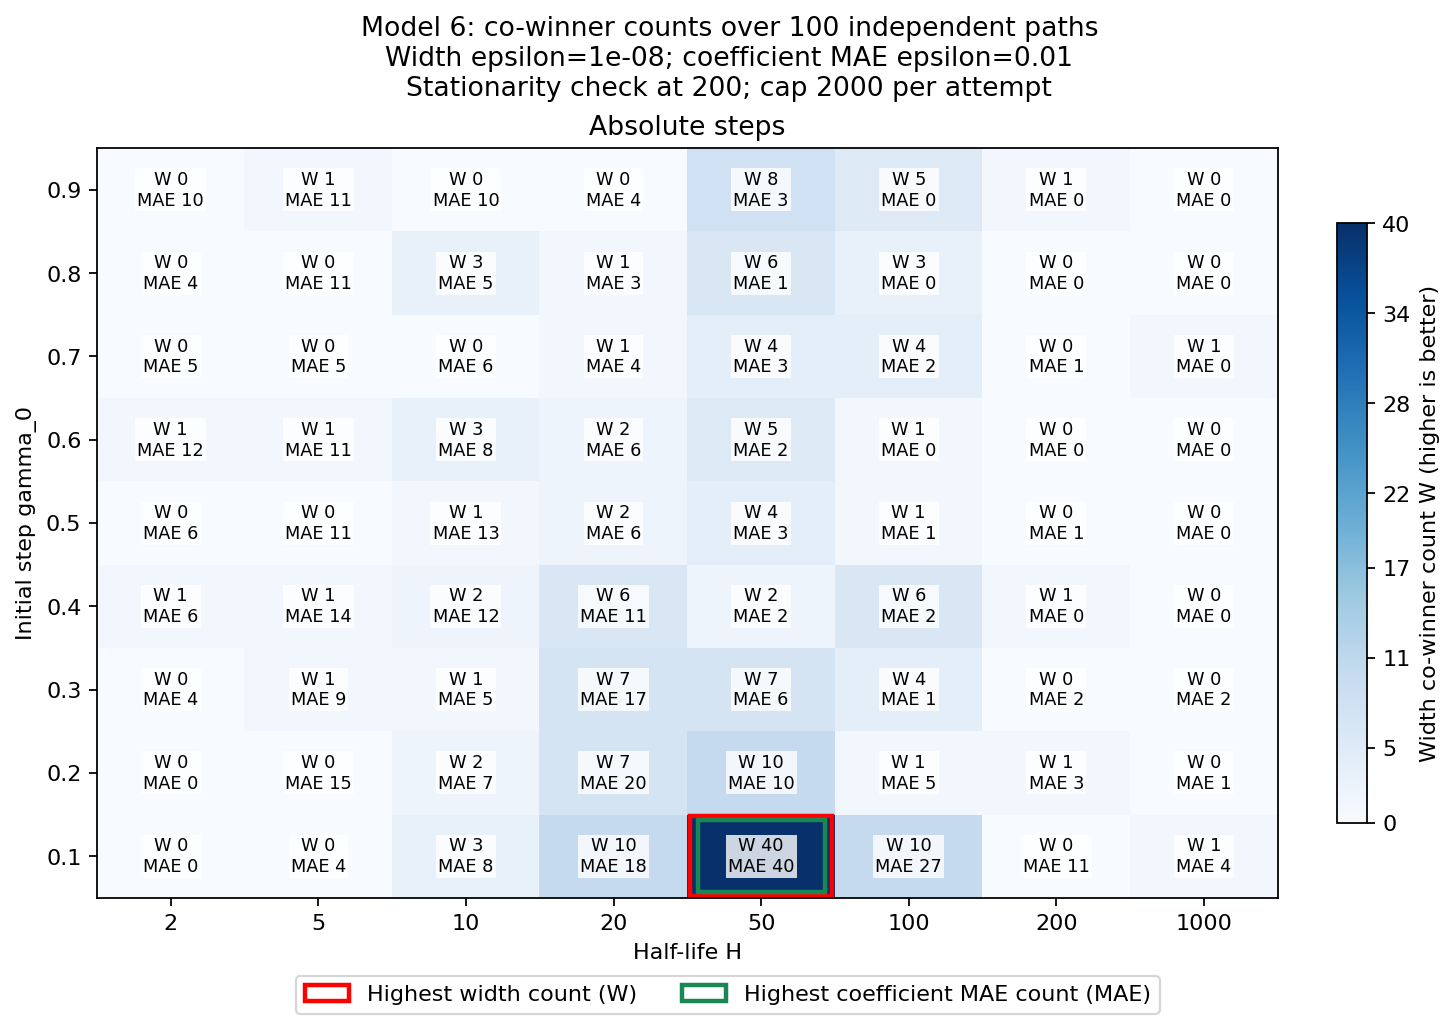

In [68]:
model6_win_figure_stem = (
    f"08_model6_width_{epsilon_win_tolerance:g}_coefficient_mae_{coefficient_epsilon_win_tolerance:g}"
)
fig, model6_win_matrices = plot_tuning_matrices(
    model6_combined_win_ranking, scale_grid, half_life_grid,
    metric="wins", secondary_metric="coefficient_wins", maximize=True, precision=0,
    title=(f"Model 6: co-winner counts over {model6_number_of_realizations} independent paths\n"
           f"Width epsilon={epsilon_win_tolerance:g}; coefficient MAE epsilon={coefficient_epsilon_win_tolerance:g}\n"
           f"Stationarity check at {patience}; cap {max_iterations} per attempt"),
    colorbar_label="Width co-winner count W (higher is better)",
    filename=model6_win_figure_stem, pdf_directory=MODEL6_PDF_DIR, image_directory=MODEL6_IMAGE_DIR,
)
plt.show()
plt.close(fig)


In [69]:
model6_selection_columns = [
    "step_value", "half_life", "beta", "wins", "coefficient_wins", "failed_runs",
    "mean_attempts", "completed_coefficient_fits", "mean_coefficient_l1_completed",
    "median_coefficient_l1_completed",
]
model6_selection = model6_combined_win_ranking.loc[
    model6_combined_win_ranking["wins"].eq(model6_combined_win_ranking["wins"].max())
    & model6_combined_win_ranking["wins"].gt(0)
].copy()
model6_previous_choice = model6_combined_win_ranking.loc[
    model6_combined_win_ranking["step_value"].eq(0.2)
    & model6_combined_win_ranking["half_life"].eq(50)
].copy()
print("Model 6: configurations with the highest width co-winner count:")
with pd.option_context("display.max_columns", None, "display.precision", 8):
    display(model6_selection[model6_selection_columns])
    print("Reference: gamma0=0.2, H=50 on these same new paths:")
    display(model6_previous_choice[model6_selection_columns])
for choice in model6_selection.to_dict("records"):
    print(f"Width winner: gamma0={choice['step_value']:g}, H={choice['half_life']:g}; "
          f"{int(choice['wins'])}/{model6_number_of_realizations} wins; "
          f"{int(choice['failed_runs'])} failed fits; "
          f"mean attempts={choice['mean_attempts']:.4f}.")
print("Coefficient L1 means/medians use only finite returned estimates; attempt means include failed fits.")
print(f"All runs: {int(model6_results['restart_limit_reached'].sum())}/{len(model6_results)} failed; "
      f"mean attempts={model6_results['attempt_count'].mean():.4f}.")
print(f"PDF matrix: {MODEL6_PDF_DIR / (model6_win_figure_stem + '.pdf')}")


Model 6: configurations with the highest width co-winner count:
Reference: gamma0=0.2, H=50 on these same new paths:
Width winner: gamma0=0.1, H=50; 40/100 wins; 5 failed fits; mean attempts=17.6700.
Coefficient L1 means/medians use only finite returned estimates; attempt means include failed fits.
All runs: 2069/7200 failed; mean attempts=41.5747.
PDF matrix: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar_tuning_experiments/model6_3f6e95da5e6cb489/08_model6_width_1e-08_coefficient_mae_0.01.pdf


,step_value,half_life,beta,wins,coefficient_wins,failed_runs,mean_attempts,completed_coefficient_fits,mean_coefficient_l1_completed,median_coefficient_l1_completed
0,0.1,50.0,0.9862327,40,40,5,17.67,95,0.53252216,0.12255756


,step_value,half_life,beta,wins,coefficient_wins,failed_runs,mean_attempts,completed_coefficient_fits,mean_coefficient_l1_completed,median_coefficient_l1_completed
3,0.2,50.0,0.9862327,10,10,72,80.94,28,1.01984965,0.12298521


## Experiment 3 repeated: data-dependent initial step $\gamma_0=c/L$

Repeat the **same 100 Jones models and their same single realizations**, common first direction and optimizer random streams. Change only the initial-step rule to $\gamma_0=c/L$, where
$$L=\max_{i,j}\|X_i-X_j\|_2$$
is the exact Euclidean diameter of the empirical four-coordinate window cloud. Compute $L$ once per model. Search $c\in\{0.1,0.2,\ldots,0.9\}$ and the existing half-life grid. This is an explicit opt-in in the [shared tuner](../ar_tools/tuning.py), `tune_geometric_half_life_schedules`; the unified optimizer still receives the resulting numerical initial step.

Keep **stationarity checking enabled**, patience 200, a fresh 2,000-evaluation budget per attempt, and up to 100 restarts. Width credits use epsilon $10^{-8}$; coefficient credits use per-coefficient MAE epsilon $10^{-2}$. Failed fits receive no credit and remain in the denominator. The matrix uses red boxes for width leaders and green boxes for coefficient-error leaders. The final comparison uses the preceding absolute-step stationarity repeat on exactly these models, reports failures and attempts, and computes raw coefficient L1 errors only where estimates are finite. [Restart implementation](../ar_tools/descent.py), `projected_subgradient_empirical_width`; [coefficient metric](../ar_tools/coefficient_errors.py), `coefficient_mae`.


In [70]:
# Refresh helpers when continuing in an already-open kernel.
tuning_tools = importlib.reload(tuning_tools)
tune_jones_ar_realizations = tuning_tools.tune_jones_ar_realizations
with plt.rc_context():
    tuning_plot_tools = importlib.reload(tuning_plot_tools)
    plot_tuning_matrices = tuning_plot_tools.plot_tuning_matrices
# Reuse the original Experiment 3 models and paths.
jones_scaled_coefficient_seed = jones_coefficient_seed
jones_scaled_process_seed = jones_process_seed
jones_scaled_check = True
jones_scaled_n_jobs = 4
jones_scaled_step_rule = "diameter_normalized"
jones_scaled_max_restarts = 100

jones_scaled_configuration = {
    "experiment": "jones_scaled_ar3_tuning", "T": int(T), "p": int(p),
    "replications": int(number_of_coefficient_realizations),
    "coefficient_sampling": "Jones1987_uniform_causal_AR3",
    "coefficient_seed": int(jones_scaled_coefficient_seed), "process_seed": int(jones_scaled_process_seed),
    "innovation_distribution": "Uniform(-1,1)", "burnin": int(burnin),
    "initial_direction": initial_direction.tolist(), "starts": 1, "optimizer_seed": int(optimizer_seed),
    "max_iterations": int(max_iterations), "patience": int(patience),
    "improvement_tolerance": float(improvement_tolerance),
    "scale_grid": scale_grid.tolist(), "half_life_grid": half_life_grid.tolist(),
    "step_rules": [jones_scaled_step_rule],
    "diameter": "max_pairwise_euclidean_distance", "parallel_workers": int(jones_scaled_n_jobs),
    "epsilon_coefficient_mae": float(coefficient_epsilon_win_tolerance),
    "stationarity_check": bool(jones_scaled_check),
    "max_restarts": int(jones_scaled_max_restarts),
    "iteration_budget": "fresh_full_budget_per_attempt",
    "epsilon": float(epsilon_win_tolerance), "selection": "most_absolute_gap_co_winner_credits",
    "source_sha256": hashlib.sha256(b"".join(
        (AR_CODE_DIR / "ar_tools" / name).read_bytes()
        for name in ["functions.py", "innovations.py", "descent.py", "tuning.py", "tuning_plots.py", "coefficient_errors.py"]
    )).hexdigest(),
}
jones_scaled_run_id = hashlib.sha256(repr(sorted(jones_scaled_configuration.items())).encode()).hexdigest()[:16]
JONES_SCALED_PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / f"jones_scaled_{jones_scaled_run_id}"
JONES_SCALED_IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / f"jones_scaled_{jones_scaled_run_id}"
for directory in (JONES_SCALED_PDF_DIR, JONES_SCALED_IMAGE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print(f"Experiment 3 with gamma0=c/L and stationarity check: {number_of_coefficient_realizations} Jones AR(3) models, T={T}; cap {max_iterations}, patience {patience}.")
print(f"Common first starting direction for every candidate and model: {initial_direction}")
print(f"Stationarity check: {jones_scaled_check}; checkpoint after {patience} evaluations per attempt; "
      f"up to {jones_scaled_max_restarts} restarts per configuration.")

print(f"Scale grid c: {scale_grid}; L is the empirical cloud diameter.")


Experiment 3 with gamma0=c/L and stationarity check: 100 Jones AR(3) models, T=500; cap 2000, patience 200.
Common first starting direction for every candidate and model: [ 0.0469043  -0.81156153  0.31282302  0.49123275]
Stationarity check: True; checkpoint after 200 evaluations per attempt; up to 100 restarts per configuration.
Scale grid c: [0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9]; L is the empirical cloud diameter.


In [71]:
jones_scaled_experiment = tune_jones_ar_realizations(
    T, initial_direction, scale_grid, half_life_grid,
    replications=number_of_coefficient_realizations,
    coefficient_seed=jones_scaled_coefficient_seed, process_seed=jones_scaled_process_seed,
    burnin=burnin, iterations=max_iterations, patience=patience,
    improvement_tolerance=improvement_tolerance, optimizer_seed=optimizer_seed, progress=True, summarize=False,
    stationarity_check=jones_scaled_check, max_restarts=jones_scaled_max_restarts,
    step_rule=jones_scaled_step_rule, n_jobs=jones_scaled_n_jobs,
)
jones_scaled_results = pd.DataFrame(jones_scaled_experiment["results"])
jones_scaled_cases = pd.DataFrame(jones_scaled_experiment["cases"])
np.testing.assert_allclose(jones_scaled_experiment["initial_direction"], initial_direction, atol=1e-15, rtol=0)
assert len(jones_scaled_cases) == number_of_coefficient_realizations
assert len(jones_scaled_results) == number_of_coefficient_realizations * len(scale_grid) * len(half_life_grid)
assert jones_scaled_results["stationarity_check"].all()
assert jones_scaled_results["stationarity_check_passed"].eq(
    ~jones_scaled_results["restart_limit_reached"]
).all()
assert np.isfinite(jones_scaled_results["minimum_width"]).eq(
    jones_scaled_results["stationarity_check_passed"]
).all()
assert jones_scaled_results["restart_count"].between(0, jones_scaled_max_restarts).all()
assert jones_scaled_results["attempt_count"].eq(jones_scaled_results["restart_count"] + 1).all()
assert jones_scaled_results["final_evaluations"].between(patience, max_iterations).all()
assert jones_scaled_results.loc[
    jones_scaled_results["stationarity_check_passed"], "checkpoint_spectral_radius"
].between(0, 1, inclusive="left").all()
np.testing.assert_array_equal(
    jones_scaled_results["total_evaluations"],
    jones_scaled_results["restart_count"] * patience + jones_scaled_results["final_evaluations"],
)
assert jones_scaled_results["selected_start"].eq(1).all()
assert jones_scaled_cases["coefficient_seed"].is_unique and jones_scaled_cases["process_seed"].is_unique
assert jones_scaled_cases[["phi_1", "phi_2", "phi_3"]].drop_duplicates().shape[0] == number_of_coefficient_realizations
assert jones_scaled_cases["spectral_radius"].between(0, 1, inclusive="left").all()
print(f"Completed {len(jones_scaled_cases)} distinct models and {len(jones_scaled_results)} paired candidate runs.")

# Verify that the repeat uses exactly the original model/path inputs.
jones_scaled_pairing_columns = [
    "replication", "T", "coefficient_seed", "process_seed", "phi_1", "phi_2", "phi_3",
    "pacf_1", "pacf_2", "pacf_3", "spectral_radius",
    "population_minimum_width", "empirical_true_direction_width",
]
pd.testing.assert_frame_equal(
    jones_stationarity_cases[jones_scaled_pairing_columns].reset_index(drop=True),
    jones_scaled_cases[jones_scaled_pairing_columns].reset_index(drop=True),
)
print(f"Restarted runs: {int(jones_scaled_results['restart_count'].gt(0).sum())}/"
      f"{len(jones_scaled_results)}; total restarts: {int(jones_scaled_results['restart_count'].sum())}.")
print(f"Total evaluated directions, including discarded attempts: "
      f"{int(jones_scaled_results['total_evaluations'].sum()):,}.")

print(f"Runs that exhausted the restart limit (no width win credit): "
      f"{int(jones_scaled_results['restart_limit_reached'].sum())}/{len(jones_scaled_results)}.")

assert jones_scaled_results["step_rule"].eq("diameter_normalized").all()
assert jones_scaled_results.groupby("replication")["cloud_diameter"].nunique().eq(1).all()
np.testing.assert_allclose(
    jones_scaled_results["gamma0"] * jones_scaled_results["cloud_diameter"],
    jones_scaled_results["step_value"], rtol=2e-15, atol=0,
)
print(f"L range: {jones_scaled_results['cloud_diameter'].min():.8g} to "
      f"{jones_scaled_results['cloud_diameter'].max():.8g}; "
      f"mean attempts={jones_scaled_results['attempt_count'].mean():.4f}.")


Path 1/100, T=500: best achieved width=0.9942104448; 72 diameter_normalized schedules; 237 restarts; 0 failed runs; 3.2s
Path 2/100, T=500: best achieved width=1.3146471482; 72 diameter_normalized schedules; 108 restarts; 0 failed runs; 2.6s
Path 3/100, T=500: best achieved width=1.2281505150; 72 diameter_normalized schedules; 29 restarts; 0 failed runs; 2.3s
Path 4/100, T=500: best achieved width=0.9716067099; 72 diameter_normalized schedules; 42 restarts; 0 failed runs; 2.2s
Path 5/100, T=500: best achieved width=0.6635217138; 72 diameter_normalized schedules; 144 restarts; 0 failed runs; 2.3s
Path 6/100, T=500: best achieved width=1.4396669267; 72 diameter_normalized schedules; 933 restarts; 6 failed runs; 6.3s
Path 7/100, T=500: best achieved width=1.8430135441; 72 diameter_normalized schedules; 281 restarts; 0 failed runs; 3.1s
Path 8/100, T=500: best achieved width=1.5937186037; 72 diameter_normalized schedules; 130 restarts; 0 failed runs; 2.2s
Path 9/100, T=500: best achieved w

In [72]:
jones_scaled_width_win_experiment = summarize_configuration_wins(
    jones_scaled_results.to_dict("records"),
    score_key="minimum_width", epsilon=epsilon_win_tolerance, allow_nonfinite=True,
)
jones_scaled_width_win_step_ranges = jones_scaled_results.groupby("candidate_id", as_index=False).agg(
    gamma0_min=("gamma0", "min"), gamma0_max=("gamma0", "max"),
    mean_attempts=("attempt_count", "mean"), total_restarts=("restart_count", "sum"),
)
jones_scaled_width_win_ranking = pd.DataFrame(jones_scaled_width_win_experiment["ranking"]).rename(
    columns={"rank": "win_rank", "undefined_scores": "failed_runs"},
).merge(jones_scaled_width_win_step_ranges, on="candidate_id", validate="one_to_one").sort_values("win_rank")
jones_scaled_width_win_leaders = jones_scaled_width_win_ranking.loc[
    jones_scaled_width_win_ranking["wins"] == jones_scaled_width_win_ranking["wins"].max()
].copy()
jones_scaled_width_win_winners = pd.DataFrame(jones_scaled_width_win_experiment["winners"])
jones_scaled_width_win_cases = pd.DataFrame(jones_scaled_width_win_experiment["case_summaries"])
assert jones_scaled_width_win_experiment["epsilon"] == epsilon_win_tolerance
assert jones_scaled_width_win_experiment["cases"] == number_of_coefficient_realizations
assert jones_scaled_width_win_ranking["wins"].between(0, number_of_coefficient_realizations).all()
assert jones_scaled_width_win_ranking["wins"].sum() == len(jones_scaled_width_win_winners) == jones_scaled_width_win_experiment["total_points"]
assert jones_scaled_width_win_cases["co_winners"].sum() == len(jones_scaled_width_win_winners)
if not jones_scaled_width_win_winners.empty:
    assert not jones_scaled_width_win_winners.duplicated(["replication", "T", "candidate_id"]).any()
    assert (jones_scaled_width_win_winners["winning_score"] <= jones_scaled_width_win_winners["winning_threshold"]).all()
    assert jones_scaled_width_win_winners["stationarity_check_passed"].all()

jones_scaled_width_win_columns = [
    "win_rank", "step_rule", "step_value", "half_life", "beta",
    "wins", "win_rate", "failed_runs", "mean_attempts", "mean_evaluations",
]

print(f"Experiment 3, gamma0=c/L: {number_of_coefficient_realizations} paths; cap {max_iterations} per attempt, patience {patience}.")
print(f"+1 to EVERY configuration with achieved width <= path minimum + {epsilon_win_tolerance:g}.")
with pd.option_context("display.max_columns", None, "display.precision", 10):
    display(jones_scaled_width_win_ranking[jones_scaled_width_win_columns].head(15))
    print("All configurations with the highest absolute-gap win count:")
    display(jones_scaled_width_win_leaders[jones_scaled_width_win_columns])
print(f"{jones_scaled_width_win_experiment['cases']} realizations; {jones_scaled_width_win_experiment['total_points']} full +1 credits; "
      f"{jones_scaled_width_win_experiment['tied_cases']} paths with multiple co-winners; "
      f"maximum {jones_scaled_width_win_experiment['maximum_co_winners']} co-winners on one path.")
for choice in jones_scaled_width_win_leaders.to_dict("records"):
    print(f"Absolute-gap win-count leader: {choice['step_rule']}, scale={choice['step_value']:g}, "
          f"H={choice['half_life']:g}, beta={choice['beta']:.12g}; "
          f"wins={int(choice['wins'])}/{number_of_coefficient_realizations}.")
print(f"Paths with no successful configuration: {jones_scaled_width_win_experiment['undefined_cases']} "
      f"(retained in the denominator).")


Experiment 3, gamma0=c/L: 100 paths; cap 2000 per attempt, patience 200.
+1 to EVERY configuration with achieved width <= path minimum + 1e-08.
All configurations with the highest absolute-gap win count:
100 realizations; 938 full +1 credits; 61 paths with multiple co-winners; maximum 32 co-winners on one path.
Absolute-gap win-count leader: diameter_normalized, scale=0.4, H=50, beta=0.986232704493; wins=52/100.
Absolute-gap win-count leader: diameter_normalized, scale=0.5, H=50, beta=0.986232704493; wins=52/100.
Paths with no successful configuration: 0 (retained in the denominator).


,win_rank,step_rule,step_value,half_life,beta,wins,win_rate,failed_runs,mean_attempts,mean_evaluations
0,1,diameter_normalized,0.4,50.0,0.9862327045,52,0.52,0,2.28,2239.12
1,2,diameter_normalized,0.5,50.0,0.9862327045,52,0.52,0,2.42,2254.24
2,3,diameter_normalized,0.6,50.0,0.9862327045,51,0.51,1,3.67,2498.11
3,4,diameter_normalized,0.3,50.0,0.9862327045,50,0.50,0,2.20,2223.11
4,5,diameter_normalized,0.7,50.0,0.9862327045,50,0.50,1,4.37,2635.74
5,6,diameter_normalized,0.8,50.0,0.9862327045,50,0.50,1,5.25,2816.69
6,7,diameter_normalized,0.9,50.0,0.9862327045,50,0.50,2,6.29,2986.27
7,8,diameter_normalized,0.2,50.0,0.9862327045,47,0.47,0,2.18,2227.21
8,9,diameter_normalized,0.1,50.0,0.9862327045,40,0.40,0,2.55,2310.00
9,10,diameter_normalized,0.1,100.0,0.9930924954,36,0.36,0,2.39,1974.06


,win_rank,step_rule,step_value,half_life,beta,wins,win_rate,failed_runs,mean_attempts,mean_evaluations
0,1,diameter_normalized,0.4,50.0,0.9862327045,52,0.52,0,2.28,2239.12
1,2,diameter_normalized,0.5,50.0,0.9862327045,52,0.52,0,2.42,2254.24


In [73]:
# Recover coefficients from each configuration's recorded minimum-width direction.
jones_scaled_coefficient_diagnostics = jones_scaled_results.copy()
jones_scaled_directions = jones_scaled_results[[f"u_{j}" for j in range(p + 1)]].to_numpy(dtype=float)
jones_scaled_coefficients = np.full((len(jones_scaled_results), p), np.nan)
jones_scaled_coefficient_valid = (
    np.isfinite(jones_scaled_directions).all(axis=1) & (np.abs(jones_scaled_directions[:, 0]) > 1e-10)
)
with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
    np.divide(-jones_scaled_directions[:, 1:], jones_scaled_directions[:, :1],
              out=jones_scaled_coefficients, where=jones_scaled_coefficient_valid[:, None])
    jones_scaled_coefficient_errors = coefficient_mae(
        jones_scaled_coefficients, jones_scaled_results[[f"phi_{j+1}" for j in range(p)]].to_numpy(),
    )
jones_scaled_coefficient_valid &= (
    np.isfinite(jones_scaled_coefficients).all(axis=1) & np.isfinite(jones_scaled_coefficient_errors)
)
jones_scaled_coefficient_errors[~jones_scaled_coefficient_valid] = np.nan
for j in range(p):
    jones_scaled_coefficient_diagnostics[f"estimated_phi_{j+1}"] = jones_scaled_coefficients[:, j]
jones_scaled_coefficient_diagnostics["coefficient_valid"] = jones_scaled_coefficient_valid
jones_scaled_coefficient_diagnostics["coefficient_mae"] = jones_scaled_coefficient_errors

jones_scaled_coefficient_win_experiment = summarize_configuration_wins(
    jones_scaled_coefficient_diagnostics.to_dict("records"), score_key="coefficient_mae",
    epsilon=coefficient_epsilon_win_tolerance, allow_nonfinite=True,
)
jones_scaled_coefficient_win_ranking = pd.DataFrame(jones_scaled_coefficient_win_experiment["ranking"]).rename(
    columns={"rank": "jones_scaled_coefficient_win_rank", "wins": "coefficient_wins",
             "win_rate": "jones_scaled_coefficient_win_rate", "undefined_scores": "undefined_coefficients"},
)
jones_scaled_coefficient_win_leaders = jones_scaled_coefficient_win_ranking.loc[
    jones_scaled_coefficient_win_ranking["coefficient_wins"] == jones_scaled_coefficient_win_ranking["coefficient_wins"].max()
].copy()
jones_scaled_coefficient_win_winners = pd.DataFrame(jones_scaled_coefficient_win_experiment["winners"])
jones_scaled_coefficient_win_cases = pd.DataFrame(jones_scaled_coefficient_win_experiment["case_summaries"])
jones_scaled_combined_win_ranking = jones_scaled_width_win_ranking.merge(
    jones_scaled_coefficient_win_ranking[["candidate_id", "jones_scaled_coefficient_win_rank", "coefficient_wins",
                             "jones_scaled_coefficient_win_rate", "undefined_coefficients"]],
    on="candidate_id", validate="one_to_one",
)
assert jones_scaled_coefficient_win_experiment["epsilon"] == coefficient_epsilon_win_tolerance
assert jones_scaled_coefficient_win_experiment["cases"] == number_of_coefficient_realizations
assert jones_scaled_coefficient_win_ranking["coefficient_wins"].between(0, number_of_coefficient_realizations).all()
assert jones_scaled_coefficient_win_ranking["coefficient_wins"].sum() == len(jones_scaled_coefficient_win_winners)
assert jones_scaled_coefficient_win_cases["co_winners"].sum() == jones_scaled_coefficient_win_experiment["total_points"]
if not jones_scaled_coefficient_win_winners.empty:
    assert not jones_scaled_coefficient_win_winners.duplicated(["replication", "T", "candidate_id"]).any()
    assert (jones_scaled_coefficient_win_winners["winning_score"] <= jones_scaled_coefficient_win_winners["winning_threshold"]).all()

jones_scaled_coefficient_win_columns = [
    "jones_scaled_coefficient_win_rank", "step_rule", "step_value", "half_life", "beta",
    "coefficient_wins", "jones_scaled_coefficient_win_rate", "undefined_coefficients",
]
print(f"+1 to EVERY configuration with coefficient MAE <= path minimum + {coefficient_epsilon_win_tolerance:g}.")
with pd.option_context("display.max_columns", None, "display.precision", 10):
    display(jones_scaled_coefficient_win_ranking[jones_scaled_coefficient_win_columns].head(15))
    print("All configurations with the highest coefficient-error win count:")
    display(jones_scaled_coefficient_win_leaders[jones_scaled_coefficient_win_columns])
print(f"{jones_scaled_coefficient_win_experiment['cases']} realizations; {jones_scaled_coefficient_win_experiment['total_points']} full +1 coefficient credits; "
      f"{jones_scaled_coefficient_win_experiment['tied_cases']} paths with multiple coefficient co-winners.")
print(f"Undefined coefficient estimates: {(~jones_scaled_coefficient_valid).sum()}; "
      f"paths with no finite coefficient estimate: {jones_scaled_coefficient_win_experiment['undefined_cases']}.")

jones_scaled_coefficient_diagnostics["coefficient_l1"] = p * jones_scaled_coefficient_diagnostics["coefficient_mae"]
jones_scaled_error_summary = jones_scaled_coefficient_diagnostics.groupby("candidate_id", as_index=False).agg(
    completed_coefficient_fits=("coefficient_l1", "count"),
    mean_coefficient_l1_completed=("coefficient_l1", "mean"),
    median_coefficient_l1_completed=("coefficient_l1", "median"),
)
jones_scaled_combined_win_ranking = jones_scaled_combined_win_ranking.merge(
    jones_scaled_error_summary, on="candidate_id", validate="one_to_one",
)


+1 to EVERY configuration with coefficient MAE <= path minimum + 0.01.
All configurations with the highest coefficient-error win count:
100 realizations; 2691 full +1 coefficient credits; 94 paths with multiple coefficient co-winners.
Undefined coefficient estimates: 63; paths with no finite coefficient estimate: 0.


,jones_scaled_coefficient_win_rank,step_rule,step_value,half_life,beta,coefficient_wins,jones_scaled_coefficient_win_rate,undefined_coefficients
0,1,diameter_normalized,0.1,200.0,0.9965402628,70,0.70,0
1,2,diameter_normalized,0.2,200.0,0.9965402628,69,0.69,0
2,3,diameter_normalized,0.2,100.0,0.9930924954,67,0.67,0
3,4,diameter_normalized,0.3,100.0,0.9930924954,67,0.67,0
4,5,diameter_normalized,0.1,100.0,0.9930924954,64,0.64,0
5,6,diameter_normalized,0.6,50.0,0.9862327045,64,0.64,1
6,7,diameter_normalized,0.4,100.0,0.9930924954,63,0.63,0
7,8,diameter_normalized,0.4,50.0,0.9862327045,62,0.62,0
8,9,diameter_normalized,0.5,50.0,0.9862327045,62,0.62,0
9,10,diameter_normalized,0.7,50.0,0.9862327045,62,0.62,1


,jones_scaled_coefficient_win_rank,step_rule,step_value,half_life,beta,coefficient_wins,jones_scaled_coefficient_win_rate,undefined_coefficients
0,1,diameter_normalized,0.1,200.0,0.9965402628,70,0.7,0


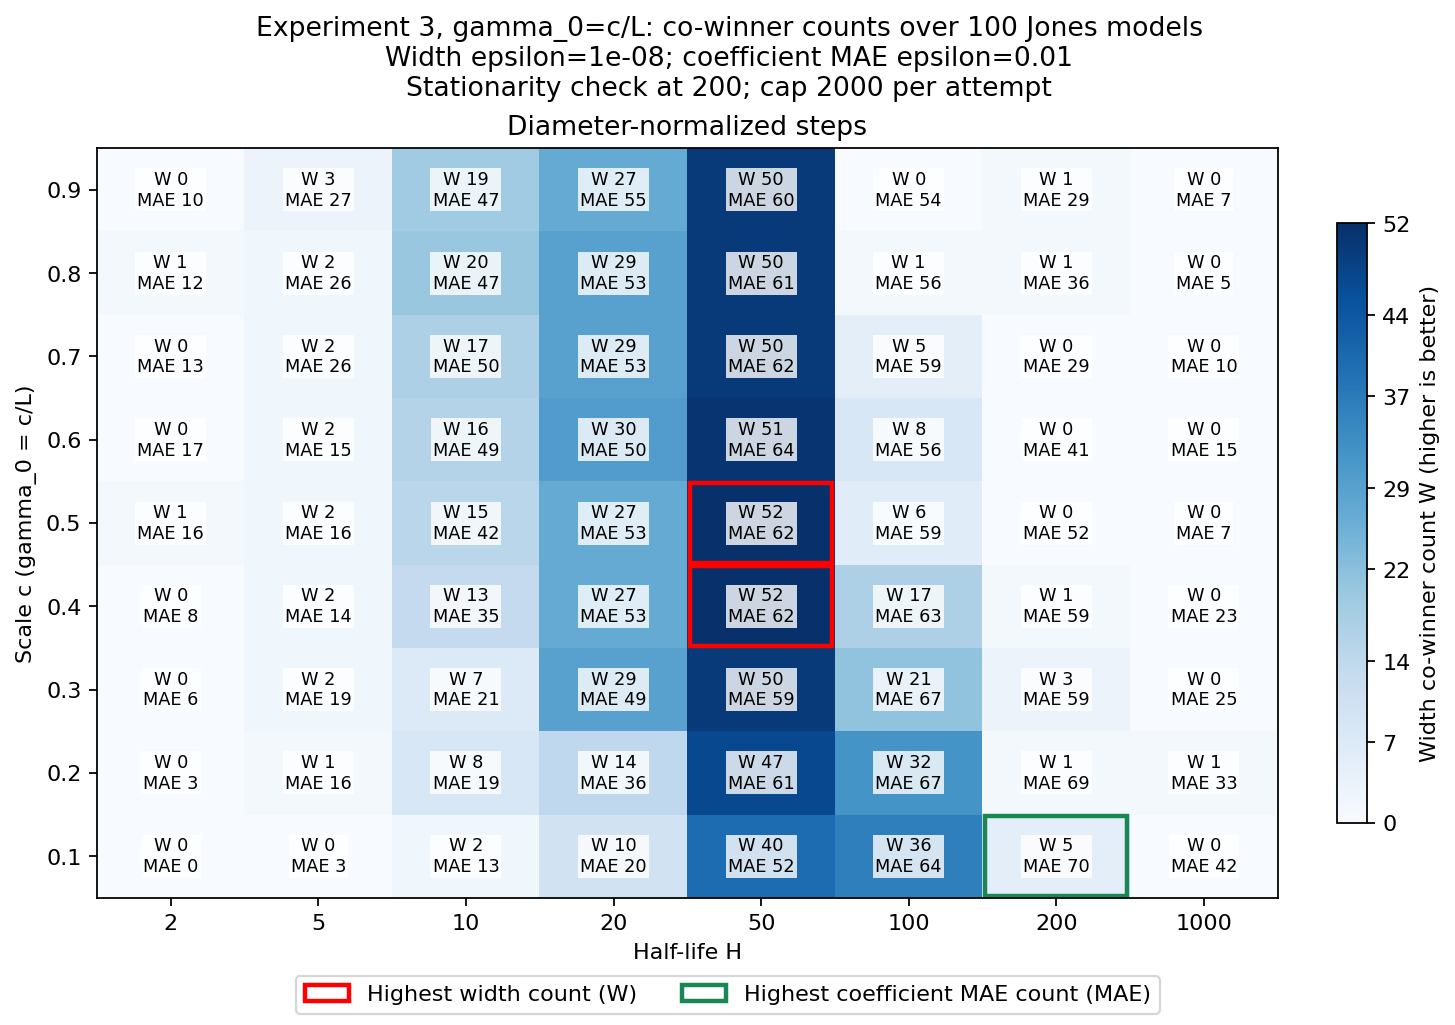

In [74]:
jones_scaled_win_figure_stem = (
    f"09_jones_scaled_width_{epsilon_win_tolerance:g}_coefficient_mae_{coefficient_epsilon_win_tolerance:g}"
)
fig, jones_scaled_win_matrices = plot_tuning_matrices(
    jones_scaled_combined_win_ranking, scale_grid, half_life_grid,
    metric="wins", secondary_metric="coefficient_wins", maximize=True, precision=0,
    title=(f"Experiment 3, gamma_0=c/L: co-winner counts over {number_of_coefficient_realizations} Jones models\n"
           f"Width epsilon={epsilon_win_tolerance:g}; coefficient MAE epsilon={coefficient_epsilon_win_tolerance:g}\n"
           f"Stationarity check at {patience}; cap {max_iterations} per attempt"),
    colorbar_label="Width co-winner count W (higher is better)",
    filename=jones_scaled_win_figure_stem, pdf_directory=JONES_SCALED_PDF_DIR, image_directory=JONES_SCALED_IMAGE_DIR,
)
plt.show()
plt.close(fig)


In [75]:
jones_scaled_selection_columns = [
    "step_value", "half_life", "beta", "wins", "coefficient_wins", "gamma0_min", "gamma0_max",
    "failed_runs", "mean_attempts", "completed_coefficient_fits",
    "mean_coefficient_l1_completed", "median_coefficient_l1_completed",
]
jones_scaled_selection = jones_scaled_combined_win_ranking.loc[
    jones_scaled_combined_win_ranking["wins"].eq(jones_scaled_combined_win_ranking["wins"].max())
    & jones_scaled_combined_win_ranking["wins"].gt(0)
].copy()
print("Experiment 3, gamma0=c/L: all width-count leaders (step_value is c):")
with pd.option_context("display.max_columns", None, "display.precision", 8):
    display(jones_scaled_selection[jones_scaled_selection_columns])
print("Coefficient L1 means/medians use finite estimates only; attempt means include failed fits.")
print(f"All runs: {int(jones_scaled_results['restart_limit_reached'].sum())}/{len(jones_scaled_results)} failed; "
      f"mean attempts={jones_scaled_results['attempt_count'].mean():.4f}.")
print(f"PDF matrix: {JONES_SCALED_PDF_DIR / (jones_scaled_win_figure_stem + '.pdf')}")


Experiment 3, gamma0=c/L: all width-count leaders (step_value is c):
Coefficient L1 means/medians use finite estimates only; attempt means include failed fits.
All runs: 63/7200 failed; mean attempts=4.6753.
PDF matrix: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar_tuning_experiments/jones_scaled_50a83d07ee68d1c1/09_jones_scaled_width_1e-08_coefficient_mae_0.01.pdf


,step_value,half_life,beta,wins,coefficient_wins,gamma0_min,gamma0_max,failed_runs,mean_attempts,completed_coefficient_fits,mean_coefficient_l1_completed,median_coefficient_l1_completed
0,0.4,50.0,0.9862327,52,62,0.00662135,0.10919786,0,2.28,100,0.22568645,0.03667757
1,0.5,50.0,0.9862327,52,62,0.00827669,0.13649733,0,2.42,100,0.21096565,0.03436332


In [76]:
# Compare the two step rules on the same model/path inputs without rerunning either grid.
jones_scaled_comparison_rows = []
jones_scaled_comparison_fits = {}
jones_scaled_comparison_leaders = {}
for rule, results in [("absolute", jones_stationarity_results),
                      ("diameter_normalized", jones_scaled_results)]:
    diagnostics = results.copy()
    directions = diagnostics[[f"u_{j}" for j in range(p + 1)]].to_numpy()
    estimates = np.full((len(diagnostics), p), np.nan)
    valid = np.isfinite(directions).all(axis=1) & (np.abs(directions[:, 0]) > 1e-10)
    with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
        np.divide(-directions[:, 1:], directions[:, :1], out=estimates, where=valid[:, None])
        diagnostics["coefficient_l1"] = p * coefficient_mae(
            estimates, diagnostics[[f"phi_{j+1}" for j in range(p)]].to_numpy(),
        )
    jones_scaled_comparison_fits[rule] = diagnostics
    width_counts = pd.DataFrame(summarize_configuration_wins(
        results.to_dict("records"), epsilon=epsilon_win_tolerance, allow_nonfinite=True,
    )["ranking"])
    leaders = width_counts.loc[width_counts["wins"].eq(width_counts["wins"].max())]
    jones_scaled_comparison_leaders[rule] = leaders
    for scope, subset in [("all 72 configurations", diagnostics)] + [
        (f"width leader: scale={choice['step_value']:g}, H={choice['half_life']:g}",
         diagnostics.loc[diagnostics["candidate_id"].eq(choice["candidate_id"])])
        for choice in leaders.to_dict("records")
    ]:
        jones_scaled_comparison_rows.append({
            "step_rule": rule, "scope": scope, "runs": len(subset),
            "failed_runs": int(subset["restart_limit_reached"].sum()),
            "mean_attempts": subset["attempt_count"].mean(),
            "finite_coefficient_estimates": int(subset["coefficient_l1"].notna().sum()),
            "mean_coefficient_l1_completed": subset["coefficient_l1"].mean(),
            "median_coefficient_l1_completed": subset["coefficient_l1"].median(),
        })
jones_scaled_comparison = pd.DataFrame(jones_scaled_comparison_rows)
print("Failures and attempts include all runs; L1 summaries condition on finite returned estimates:")
with pd.option_context("display.max_columns", None, "display.precision", 8):
    display(jones_scaled_comparison)

# Error changes on a common finite subset, for every pair of width-count leaders.
jones_scaled_paired_rows = []
for before in jones_scaled_comparison_leaders["absolute"].to_dict("records"):
    for after in jones_scaled_comparison_leaders["diameter_normalized"].to_dict("records"):
        paired = jones_scaled_comparison_fits["absolute"].loc[
            lambda frame: frame["candidate_id"].eq(before["candidate_id"])
        ].merge(jones_scaled_comparison_fits["diameter_normalized"].loc[
            lambda frame: frame["candidate_id"].eq(after["candidate_id"])
        ], on=["replication", "T"], suffixes=("_absolute", "_scaled"), validate="one_to_one")
        finite = paired["coefficient_l1_absolute"].notna() & paired["coefficient_l1_scaled"].notna()
        width_finite = paired["minimum_width_absolute"].notna() & paired["minimum_width_scaled"].notna()
        jones_scaled_paired_rows.append({
            "absolute_gamma0": before["step_value"], "absolute_H": before["half_life"],
            "scaled_c": after["step_value"], "scaled_H": after["half_life"],
            "common_finite_estimates": int(finite.sum()),
            "mean_L1_absolute": paired.loc[finite, "coefficient_l1_absolute"].mean(),
            "mean_L1_scaled": paired.loc[finite, "coefficient_l1_scaled"].mean(),
            "median_L1_absolute": paired.loc[finite, "coefficient_l1_absolute"].median(),
            "median_L1_scaled": paired.loc[finite, "coefficient_l1_scaled"].median(),
            "common_finite_widths": int(width_finite.sum()),
            "scaled_narrower_beyond_epsilon": int((width_finite & (
                paired["minimum_width_scaled"] < paired["minimum_width_absolute"] - epsilon_win_tolerance)).sum()),
            "absolute_narrower_beyond_epsilon": int((width_finite & (
                paired["minimum_width_absolute"] < paired["minimum_width_scaled"] - epsilon_win_tolerance)).sum()),
        })
jones_scaled_paired_comparison = pd.DataFrame(jones_scaled_paired_rows)
print("Paired comparison of width-count leaders on their common finite models:")
with pd.option_context("display.max_columns", None, "display.precision", 8):
    display(jones_scaled_paired_comparison)

# A common 144-configuration contest makes width counts comparable across rules.
jones_scaled_union = pd.concat([jones_stationarity_results, jones_scaled_results], ignore_index=True)
jones_scaled_union_counts = pd.DataFrame(summarize_configuration_wins(
    jones_scaled_union.to_dict("records"), epsilon=epsilon_win_tolerance, allow_nonfinite=True,
)["ranking"])
print("Width-count ranking in the combined absolute + c/L grid (144 configurations):")
with pd.option_context("display.max_columns", None, "display.precision", 8):
    display(jones_scaled_union_counts[["step_rule", "step_value", "half_life", "wins", "undefined_scores"]].head(15))


Failures and attempts include all runs; L1 summaries condition on finite returned estimates:
Paired comparison of width-count leaders on their common finite models:
Width-count ranking in the combined absolute + c/L grid (144 configurations):


,step_rule,scope,runs,failed_runs,mean_attempts,finite_coefficient_estimates,mean_coefficient_l1_completed,median_coefficient_l1_completed
0,absolute,all 72 configurations,7200,198,7.04277778,7002,1.77849002,0.18640905
1,absolute,"width leader: scale=0.2, H=50",100,6,11.64000000,94,0.60007037,0.04707913
2,diameter_normalized,all 72 configurations,7200,63,4.67527778,7137,0.52652640,0.11018969
3,diameter_normalized,"width leader: scale=0.4, H=50",100,0,2.28000000,100,0.22568645,0.03667757
4,diameter_normalized,"width leader: scale=0.5, H=50",100,0,2.42000000,100,0.21096565,0.03436332


,absolute_gamma0,absolute_H,scaled_c,scaled_H,common_finite_estimates,mean_L1_absolute,mean_L1_scaled,median_L1_absolute,median_L1_scaled,common_finite_widths,scaled_narrower_beyond_epsilon,absolute_narrower_beyond_epsilon
0,0.2,50.0,0.4,50.0,94,0.60007037,0.20864214,0.04707913,0.03074821,94,23,24
1,0.2,50.0,0.5,50.0,94,0.60007037,0.21801995,0.04707913,0.02920702,94,25,24


,step_rule,step_value,half_life,wins,undefined_scores
0,diameter_normalized,0.4,50.0,51,0
1,diameter_normalized,0.5,50.0,51,0
2,diameter_normalized,0.6,50.0,50,1
3,diameter_normalized,0.7,50.0,50,1
4,diameter_normalized,0.9,50.0,50,2
5,absolute,0.1,50.0,49,3
6,absolute,0.3,50.0,49,8
7,diameter_normalized,0.8,50.0,49,1
8,absolute,0.2,50.0,48,6
9,diameter_normalized,0.3,50.0,48,0
